# 2026 年中国研究生数学建模竞赛 F 题 · 问题四
## 技术演进分析与前沿预测 —— 双时间轴、暴露校正与滚动回测创新版

> **赛题要求（保持不变）**：大语言模型能力的提升既来自 **规模扩张**，也来自 **非规模技术进步**（架构改进、对齐方法、数据工程等）。结合附件 C 建立动力学模型或因果推断模型，**分离并分别量化** 二者的贡献占比；在 **算力增长放缓** 的情景下，预测未来 12 或 24 个月开源大语言模型能力的前沿边界，并给出不确定性分析。须说明综合能力、开源筛选、模型类型、时间轴口径，并利用 C6/C5 讨论 Loss–Benchmark 桥接误差；C8 必须进行逐任务聚合分析。

### 本创新版与原版的关系

本 notebook **不改变任务、不更换附件、不改变前三问接口、不改变官方数据划分**。原版中已经处理较好的模块（C1 六维等权综合分、C8 子任务重建、pretrained/chat 分层、Shapley 分解、C3 长周期、C6 logistic 桥接、问题三 $L^\star(C)$ 接口）全部保留；创新仅针对原版中最容易产生识别偏差与预测不稳定的位置升级，并把原方法保留为 baseline 参与竞争。

### 三个主创新

1. **DATF：Delay-Aware Dual-Time Frontier（双时间轴前沿模型）**  
   发布日期 $t^{pub}$ 表示模型技术年代，排行榜提交延迟 $d=t^{submit}-t^{pub}$ 单独进入模型，避免把“社区扩散/评测延迟”全部误记为算法进步：
   $$Q_{0.9}(y_i)=\beta_0+\beta_C\ln C_i+\gamma_{tech}t_i^{pub}+\rho d_i+\delta I_i^{chat},\qquad y_i=\mathrm{logit}(S_i/100).$$
   同时保留原 OLS 和不含延迟项的 q=0.9 模型作为 baseline/ablation。

2. **EARF：Exposure-Aware Record Frontier（暴露校正记录前沿）**  
   原版用 $\ln(1+t)$ 描述纪录刷新减速；创新版进一步把“时间过去了多久”和“累计出现了多少个候选模型”分开：
   $$\mathrm{logit}(F_g(t)/100)=a_g+b_g\ln(1+M_g(t))+c_gt,$$
   其中 $M_g(t)$ 为截至 $t$ 的累计可比较开源模型数。这样可以区分“候选池扩大导致更容易刷出极值”和“模型分布整体右移的技术进步”。

3. **ROAE：Rolling-Origin Adaptive Ensemble + residual calibration（滚动回测自适应融合与区间校准）**  
   用多个历史截断点进行滚动时序回测，候选集包含 **原版 A、创新 A、原版 B、q90-B、DATF-B**。权重由样本外 MAE 的指数权重决定；若创新集成在回测上不优于最佳原 baseline，则自动回退到 baseline，避免“为创新而创新”。Bootstrap 区间再用滚动回测绝对残差做 conformal-inspired 校准。

### 技术路线

```text
C1/C2/C8 ─► 综合能力 S + 开源/类型/时间口径 ─► 记录前沿 F(t)
   │                                              ├─ 原 A：logit F ~ log(1+t)
   │                                              └─ 创新 EARF：logit F ~ log(1+M(t)) + t
   ├─ C8 39 个叶子任务 ─► task-level bootstrap stability ─► 稳定的“规模/技术驱动”图谱
   │
C4 ─► 训练算力 C + 发布日期 ─► OLS / q90 / DATF 三模型竞争
   │                         └─ 数据驱动变化点 ─► 算力增长 延续/放缓/停滞 三情景
   │
C6 + 问题三 L*(C) ─► 自适应异方差 Loss–Benchmark 桥接 ─► “Loss 链条未解释增益”交叉核对
   │
   └──────────────────────────────────────────────► rolling-origin 多折回测
                                                     ├─ softmax(MAE) 自适应融合
                                                     ├─ baseline safeguard
                                                     └─ Bootstrap + rolling-residual 校准
                                                          └─ 12/24 月前沿与概率矩阵
```

### 参考方法来源（详细文献列于末尾）

- Ho et al., *Algorithmic Progress in Language Models*, 2024：augmented scaling law / 等效算力视角。
- Koenker & Bassett, *Regression Quantiles*, Econometrica 1978：分位数回归。
- Hoffmann et al., *Training Compute-Optimal Large Language Models*, NeurIPS 2022：计算预算与参数/数据规模的联合视角。
- Romano et al., *Conformalized Quantile Regression*, NeurIPS 2019；Gibbs & Candès, *Adaptive Conformal Inference Under Distribution Shift*, NeurIPS 2021：预测区间校准思想。
- Hyndman & Athanasopoulos, *Forecasting: Principles and Practice*：rolling forecasting origin / time-series cross-validation。


In [20]:
# ============ 0. 环境配置 ============
import os, sys, json, math, time, warnings, itertools, lzma, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Patch, Rectangle, Polygon, FancyBboxPatch
from matplotlib.lines import Line2D
import seaborn as sns
from scipy import stats
from scipy.optimize import linprog, least_squares, minimize, brentq
from scipy.special import expit, logit

warnings.filterwarnings('ignore')
import logging
logging.getLogger('matplotlib').setLevel(logging.ERROR); logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40); pd.set_option('display.float_format', lambda v: '%.4f' % v)

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Noto Sans CJK SC', 'Noto Sans CJK JP']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 110; plt.rcParams['savefig.dpi'] = 300; plt.rcParams['savefig.bbox'] = 'tight'
plt.rcParams['axes.spines.top'] = False; plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.grid'] = True; plt.rcParams['grid.color'] = '#E4E4E4'; plt.rcParams['grid.linewidth'] = 0.6
plt.rcParams['axes.edgecolor'] = '#555555'; plt.rcParams['axes.titleweight'] = 'bold'; plt.rcParams['font.size'] = 10

C_NAVY, C_TEAL, C_CORAL, C_GOLD, C_PLUM, C_GREY, C_MOSS, C_RUST = '#1F3A5F', '#2A9D8F', '#E76F51', '#E9C46A', '#6D597A', '#9E9E9E', '#8AB17D', '#7A1F1F'
COL_TYPE = {'pretrained': C_NAVY, 'chat/finetuned': C_CORAL}; NAME_TYPE = {'pretrained': 'pretrained（预训练基础模型）', 'chat/finetuned': 'chat / finetuned（对话或微调模型）'}
FAM_COLORS = {'BBH': '#1F3A5F', 'GPQA': '#6D597A', 'IFEval': '#2A9D8F', 'MATH': '#E76F51', 'MMLU-PRO': '#E9C46A', 'MUSR': '#8AB17D'}
CMAP_DENS = mpl.colors.LinearSegmentedColormap.from_list('dens', ['#FFFFFF', '#E3ECF3', '#B7CFE0', '#7FA8C9', '#3F6E9E', '#1F3A5F'])
CMAP_HEAT = mpl.colors.LinearSegmentedColormap.from_list('heat', ['#F7F9FB', '#FCE3D3', '#F2A07B', '#E76F51', '#7A1F1F'])
CMAP_TIME = mpl.colors.LinearSegmentedColormap.from_list('time', ['#0B2545', '#2A9D8F', '#E9C46A', '#E76F51'])
plain = mpl.ticker.FuncFormatter(lambda v, _: '%g' % v); pow10 = mpl.ticker.FuncFormatter(lambda v, _: '1e%d' % int(round(np.log10(v))))
RNG = np.random.default_rng(2026)
N_BOOT = 200                 # 主模型 Bootstrap 次数；比赛最终版可提高到 500
N_BOOT_TASK = 100            # C8 任务稳定性 Bootstrap
ALPHA_PI = 0.10              # 90% 预测区间

BASE_DIR = Path('..').resolve(); CDIR = BASE_DIR / 'real_attachments' / 'C_efficiency_evolution'; C8DIR = CDIR / 'c8_cache'
for p_, msg in ((CDIR / 'leaderboard_cleaned.csv', 'C1'), (CDIR / 'epoch_all_ai_models.csv', 'C4'), (C8DIR / 'c8_task_scores_wide.csv.xz', 'C8 聚合缓存（请先双击 run_aggregate_c8.bat）'),
                (BASE_DIR / 'output_q2' / 'tables' / 'q2_outputs_for_q3.json', '问题二接口'), (BASE_DIR / 'output_q3' / 'tables' / 'q3_outputs_for_q4.json', '问题三接口')):
    if not p_.exists(): raise FileNotFoundError('未找到 %s: %s' % (msg, p_))
Q2 = json.load(open(BASE_DIR / 'output_q2' / 'tables' / 'q2_outputs_for_q3.json', encoding='utf-8')); Q3 = json.load(open(BASE_DIR / 'output_q3' / 'tables' / 'q3_outputs_for_q4.json', encoding='utf-8'))
OUT = BASE_DIR / 'output_q4_innov'; FIG = OUT / 'figures'; TAB = OUT / 'tables'
for d in (FIG, TAB): d.mkdir(parents=True, exist_ok=True)
def savefig(name): plt.savefig(FIG / name, dpi=300, bbox_inches='tight')
T0 = pd.Timestamp('2024-06-01')                                   # 时间原点：排行榜首月
def tau(d): return (pd.to_datetime(d) - T0).dt.days / 30.4375       # 以月为单位的时间
print('附件 C 目录:', CDIR); print('C8 缓存:', C8DIR)

附件 C 目录: D:\华为杯研究生建模资料\第二十三届中国研究生数学建模竞赛 - 中文题目\中文题目\F题\real_attachments\C_efficiency_evolution
C8 缓存: D:\华为杯研究生建模资料\第二十三届中国研究生数学建模竞赛 - 中文题目\中文题目\F题\real_attachments\C_efficiency_evolution\c8_cache


## 1. 数据台账与四个口径：保留原版定义，新增“发布—提交延迟”诊断

### 1.1 综合能力 $S$
排行榜 6 个维度（IFEval、BBH、MATH Lvl 5、GPQA、MUSR、MMLU-PRO）已按“减去随机基线再除以余量”归一到 0–100，`Average` 是六者等权平均。本问仍以其作为主综合能力 $S$，并用 C8 的叶子任务独立重建 $S^{C8}$ 做稳健性检验。建模统一使用
$$y=\operatorname{logit}(S/100),$$
以满足得分上界并缓解高分区饱和。

### 1.2 开源筛选、模型类型与时间轴
- **严口径（主用）**：许可证明确允许研究与复现；`other` / `unknown` / 缺失剔除。
- **宽口径（敏感性）**：只要求排行榜可获得权重。
- **模型类型**：`pretrained` 与 `chat/finetuned` 分开建模。
- **提交日期**：表示能力“被排行榜观察到”的时间；用于记录流与前沿包络。
- **Epoch 发布日期**：表示模型进入公共技术生态的时间；用于技术年代识别。
- **新增延迟变量**：$d_i=(t_i^{submit}-t_i^{pub})/\text{month}$，用于检验原版时间趋势中混入多少“发布后扩散/评测延迟”。

### 1.3 数据完整性原则
附件和前三问接口保持原样；所有新结果写入 `output_q4_innov/`，不会覆盖原版 `output_q4/`。凡创新模型在滚动回测上没有达到 baseline，将自动回退，因此“创新”不以牺牲可验证表现为代价。


C1 原始 4576 行；有效（参数量>0、有提交日期、类型可比）4552 行；剔除 24 行

模型数（按类型 x 口径）:


,全部,宽口径（权重开源）,严口径（许可证允许研究与复现）
type,,,
chat/finetuned,4222,4222,2257
pretrained,330,330,241
合计,4552,4552,2498


许可证分布（前 15）:


,n,严口径,最高分
lic,,,
missing,1750,False,47.3684
apache-2.0,1465,True,47.4644
other,293,False,52.0814
mit,283,True,51.2313
llama3.1,178,True,43.4138
cc-by-nc-4.0,125,True,40.4050
gemma,123,True,36.1743
llama3.2,121,True,24.2047
llama3,118,True,38.6961


与 Epoch AI 开源权重字段交叉核对: 匹配 442 个模型，其中 Open_Weights=Yes 424, No 18；严口径与 Epoch=Yes 的一致率 60.1%
时间轴口径: 提交日期 - Epoch 发布日期（446 个可比模型）: 中位 104 天, 四分位 [36, 172]；C8 评测时间 - 提交日期（1886 个）: 中位 0 天

pretrained 前沿记录（严口径；首行 = 首月初始批次的最高者）:


,date,Model,N_B,S
0,2024-06-12,01-ai/Yi-1.5-34B-32K,34.3890,26.7279
1,2024-08-07,dnhkng/RYS-Phi-3-medium-4k-instruct,17.7090,29.0937
2,2024-09-19,Qwen/Qwen2.5-14B,14.7700,31.9511
3,2024-09-19,Qwen/Qwen2.5-32B,32.7640,38.0080



chat/finetuned 前沿记录（严口径；首行 = 首月初始批次的最高者）:


,date,Model,N_B,S
0,2024-06-27,gbueno86/Meta-LLama-3-Cat-Smaug-LLama-70b,70.5540,38.6961
1,2024-08-07,dnhkng/RYS-XLarge,77.9650,45.3452
2,2024-09-03,MaziyarPanahi/calme-2.4-rys-78b,77.9650,50.7650
3,2024-09-24,dfurman/CalmeRys-78B-Orpo-v0.1,77.9650,51.2313


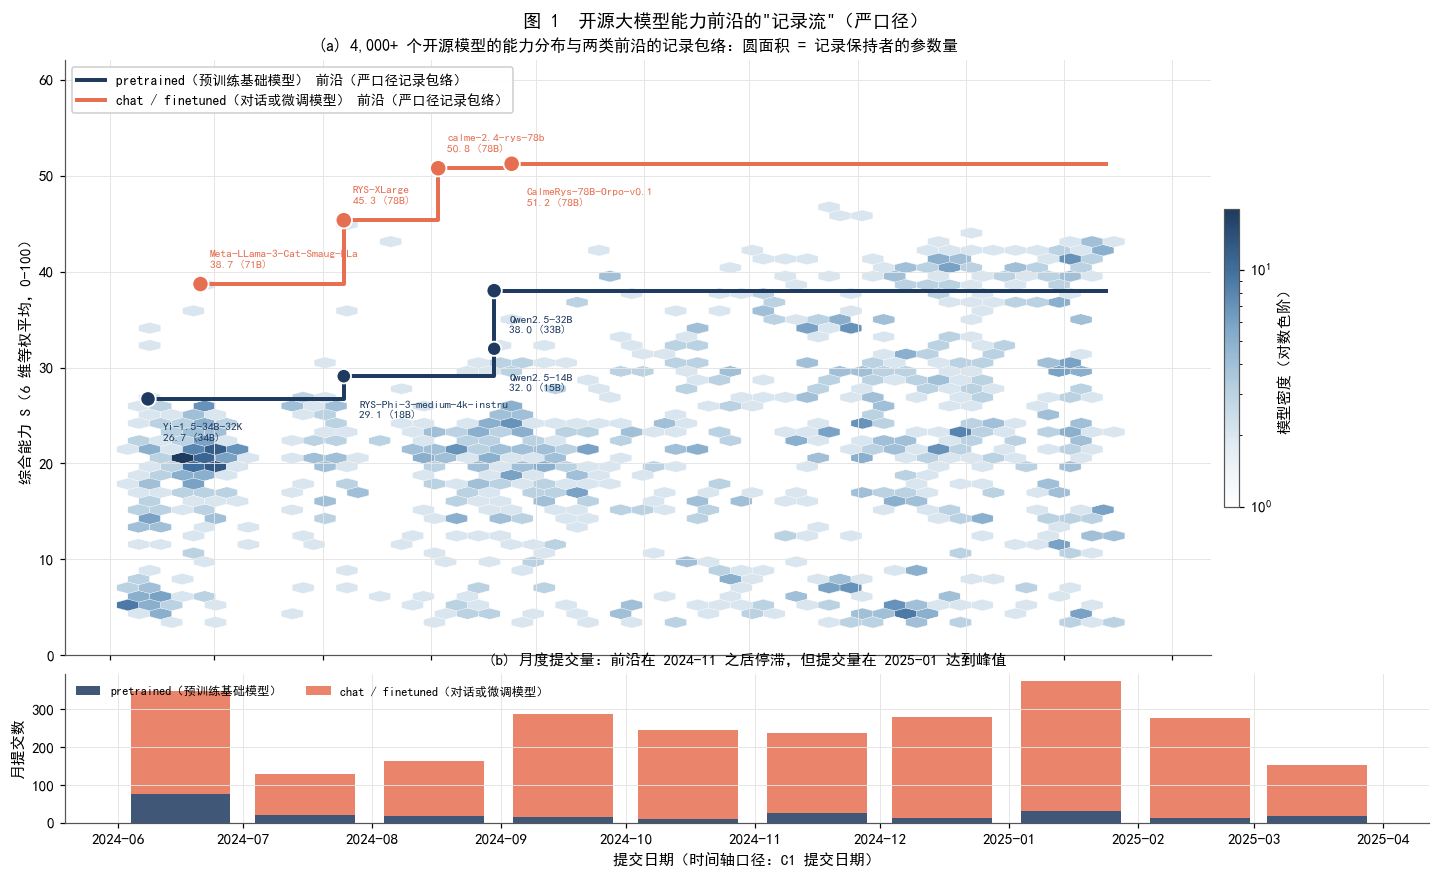

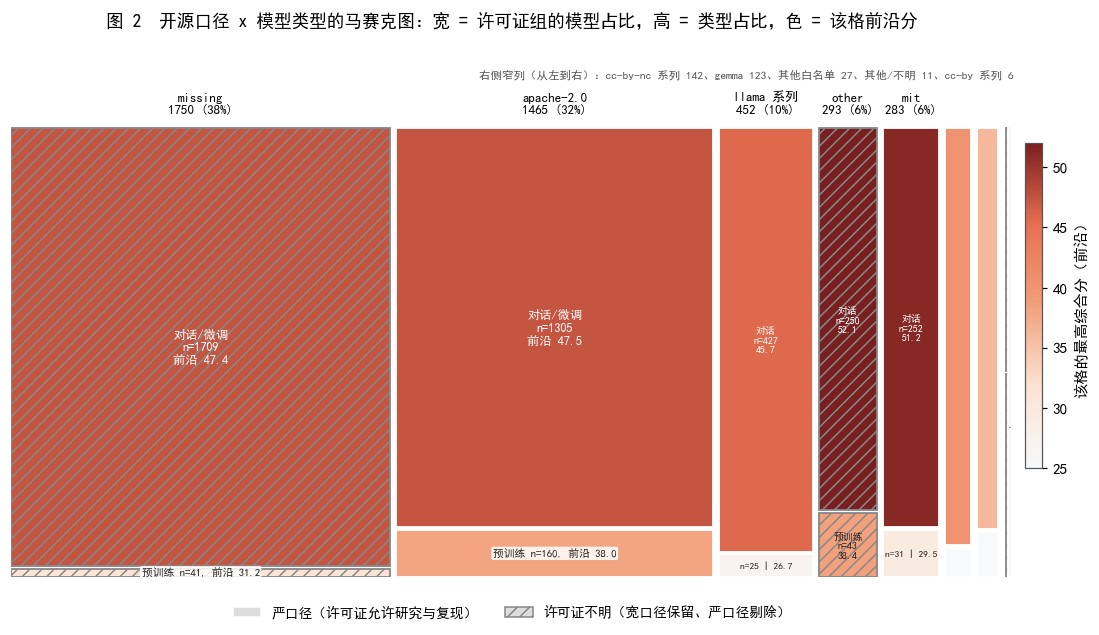

In [21]:
# ============ 1. 读取附件 C、建立分析表 ============
C1 = pd.read_csv(CDIR / 'leaderboard_cleaned.csv'); C2 = pd.read_csv(CDIR / 'leaderboard_enhanced.csv'); C3 = pd.read_csv(CDIR / 'leaderboard_extended_timeseries.csv')
C4 = pd.read_csv(CDIR / 'epoch_all_ai_models.csv'); C6 = pd.read_csv(CDIR / 'loss_benchmark_bridge_expanded.csv'); C5 = pd.read_csv(CDIR / 'loss_benchmark_bridge.csv'); C7 = pd.read_csv(CDIR / 'model_architecture_metadata.csv')
C8W = pd.read_csv(lzma.open(C8DIR / 'c8_task_scores_wide.csv.xz')); C8M = pd.read_csv(C8DIR / 'c8_meta.csv'); C8CFG = json.load(open(C8DIR / 'c8_task_config.json', encoding='utf-8'))
DIMS = ['IFEval', 'BBH', 'MATH Lvl 5', 'GPQA', 'MUSR', 'MMLU-PRO']
LB = C1.rename(columns={'Average ⬆️': 'S', '#Params (B)': 'N_B', 'Submission Date': 'date_sub', 'Hub License': 'license', 'Type': 'type_raw'}).copy()
LB['date_sub'] = pd.to_datetime(LB['date_sub'], errors='coerce'); LB['tau'] = tau(LB['date_sub'])
def type_group(t):
    t = str(t)
    if 'pretrained' in t: return 'pretrained'
    if any(k in t for k in ('chat', 'fine-tuned', 'merges')): return 'chat/finetuned'
    return 'other'
LB['type'] = LB['type_raw'].map(type_group)
LIC_OK = {'apache-2.0', 'mit', 'llama2', 'llama3', 'llama3.1', 'llama3.2', 'llama3.3', 'gemma', 'cc-by-4.0', 'cc-by-sa-4.0', 'cc-by-nc-4.0', 'cc-by-nc-sa-4.0', 'cc-by-nc-nd-4.0', 'bigscience-bloom-rail-1.0', 'bigscience-openrail-m', 'creativeml-openrail-m', 'openrail', 'gpl-3.0', 'agpl-3.0', 'lgpl-3.0', 'bsd-3-clause', 'bsd-2-clause', 'cc0-1.0', 'artistic-2.0', 'mpl-2.0', 'openrail++', 'llama-2', 'wtfpl', 'unlicense', 'deepseek', 'yi-license'}
LB['lic'] = LB['license'].fillna('missing').str.lower().str.strip()
LB['open_strict'] = LB['lic'].isin(LIC_OK); LB['open_broad'] = True
LB = LB.merge(C2[['Model', 'Epoch_AI_Publication_Date', 'Epoch_AI_Open_Weights', 'Epoch_AI_Organization']].drop_duplicates('Model'), on='Model', how='left')
LB['date_pub'] = pd.to_datetime(LB['Epoch_AI_Publication_Date'], errors='coerce')
C8M['Model'] = C8M['model_name']; C8M['date_eval'] = pd.to_datetime(C8M['date_unix'], unit='s', errors='coerce')
LB = LB.merge(C8M[['Model', 'model_dir', 'date_eval', 'model_num_parameters']].drop_duplicates('Model'), on='Model', how='left')
valid = (LB['N_B'] > 0) & LB['date_sub'].notna() & LB['S'].notna() & (LB['type'] != 'other')
print('C1 原始 %d 行；有效（参数量>0、有提交日期、类型可比）%d 行；剔除 %d 行' % (len(LB), valid.sum(), (~valid).sum()))
LB = LB[valid].copy(); LB['lnN'] = np.log(LB['N_B'] * 1e9); LB['y'] = logit(np.clip(LB['S'] / 100, 1e-3, 1 - 1e-3))
# 口径统计
tab = pd.DataFrame({'全部': LB.groupby('type').size(), '宽口径（权重开源）': LB[LB.open_broad].groupby('type').size(), '严口径（许可证允许研究与复现）': LB[LB.open_strict].groupby('type').size()})
tab.loc['合计'] = tab.sum(); print('\n模型数（按类型 x 口径）:'); display(tab)
lic_tab = LB.groupby('lic').agg(n=('Model', 'size'), 严口径=('open_strict', 'first'), 最高分=('S', 'max')).sort_values('n', ascending=False); print('许可证分布（前 15）:'); display(lic_tab.head(15))
m_ = LB['Epoch_AI_Open_Weights'].notna(); print('与 Epoch AI 开源权重字段交叉核对: 匹配 %d 个模型，其中 Open_Weights=Yes %d, No %d；严口径与 Epoch=Yes 的一致率 %.1f%%' % (m_.sum(), (LB.loc[m_, 'Epoch_AI_Open_Weights'] == 'Yes').sum(), (LB.loc[m_, 'Epoch_AI_Open_Weights'] == 'No').sum(), 100 * (LB.loc[m_ & (LB['Epoch_AI_Open_Weights'] == 'Yes'), 'open_strict']).mean()))
# 时间轴口径：三个时间的滞后
lag_pub = (LB['date_sub'] - LB['date_pub']).dt.days; lag_eval = (LB['date_eval'] - LB['date_sub']).dt.days
LB['lag_pub_submit_month'] = lag_pub / 30.4375
print('时间轴口径: 提交日期 - Epoch 发布日期（%d 个可比模型）: 中位 %.0f 天, 四分位 [%.0f, %.0f]；C8 评测时间 - 提交日期（%d 个）: 中位 %.0f 天' % (lag_pub.notna().sum(), lag_pub.median(), lag_pub.quantile(.25), lag_pub.quantile(.75), lag_eval.notna().sum(), lag_eval.median()))
LB.to_csv(TAB / 'leaderboard_analysis_table.csv', index=False, encoding='utf-8-sig'); tab.to_csv(TAB / 'open_source_criteria_counts.csv', encoding='utf-8-sig')

# 记录包络（前沿）：按类型、严口径，累计最大值及其保持者
def envelope(df, init_end='2024-06-30'):
    """记录包络：首月（排行榜 v2 上线时集中提交的历史模型）视为初始批次，取其最高者为起点；之后逐条刷新记录"""
    d = df.sort_values(['date_sub', 'S']).reset_index(drop=True); init = d[d['date_sub'] <= init_end]; r0 = init.loc[init['S'].idxmax()]
    rows = [{'date': r0['date_sub'], 'tau': r0['tau'], 'S': r0['S'], 'Model': r0['Model'], 'N_B': r0['N_B'], 'type': r0['type'], 'init_batch': True}]; best = r0['S']
    for _, r in d[d['date_sub'] > init_end].iterrows():
        if r['S'] > best: best = r['S']; rows.append({'date': r['date_sub'], 'tau': r['tau'], 'S': r['S'], 'Model': r['Model'], 'N_B': r['N_B'], 'type': r['type'], 'init_batch': False})
    return pd.DataFrame(rows)
ENV = {g: envelope(LB[(LB['type'] == g) & LB['open_strict']]) for g in ('pretrained', 'chat/finetuned')}
for g, e in ENV.items(): print('\n%s 前沿记录（严口径；首行 = 首月初始批次的最高者）:' % g); display(e[['date', 'Model', 'N_B', 'S']])

# ---- 图 1：能力前沿的"记录流"：全部模型的密度 + 两类前沿的记录包络 + 月度提交量 ----
fig = plt.figure(figsize=(16, 9)); gs = gridspec.GridSpec(2, 1, height_ratios=[4, 1], hspace=0.05)
ax = fig.add_subplot(gs[0]); d_ = LB[LB.open_strict]
hb = ax.hexbin(mpl.dates.date2num(d_['date_sub']) + RNG.uniform(-6, 6, len(d_)), d_['S'], gridsize=(46, 28), cmap=CMAP_DENS, mincnt=1, linewidths=0.2, edgecolors='white', bins='log')
for g, c in COL_TYPE.items():
    e = ENV[g]; xs = mpl.dates.date2num(e['date']); ys = e['S'].values
    xs2 = np.append(xs, mpl.dates.date2num(d_['date_sub'].max())); ys2 = np.append(ys, ys[-1])
    ax.step(xs2, ys2, where='post', color=c, lw=2.6, zorder=5, label='%s 前沿（严口径记录包络）' % NAME_TYPE[g])
    ax.scatter(xs, ys, s=[40 + 12 * np.log2(max(n, 0.1)) for n in e['N_B']], color=c, edgecolor='white', linewidths=1.2, zorder=6)
    for k, r in e.iterrows():                                      # 记录保持者标签
        if k == 0 or r['S'] - e['S'].iloc[k - 1] > 0.4 or k == len(e) - 1:
            ax.annotate('%s\n%.1f (%.0fB)' % (r['Model'].split('/')[-1][:26], r['S'], r['N_B']), (mpl.dates.date2num(r['date']), r['S']), xytext=(6, 10) if (g == 'chat/finetuned' and k != len(e) - 1) else (10, -16), textcoords='offset points', fontsize=7.5, color=c, ha='left', va='bottom' if (g == 'chat/finetuned' and k != len(e) - 1) else 'top')
ax.set_ylabel('综合能力 S（6 维等权平均，0-100）'); ax.set_ylim(0, 62); ax.tick_params(labelbottom=False)
cb = plt.colorbar(hb, ax=ax, shrink=0.5, pad=0.01); cb.set_label('模型密度（对数色阶）')
ax.legend(loc='upper left', frameon=True, fontsize=9, facecolor='white', framealpha=0.95)
ax.set_title('(a) 4,000+ 个开源模型的能力分布与两类前沿的记录包络：圆面积 = 记录保持者的参数量', fontsize=10.5)
ax2 = fig.add_subplot(gs[1], sharex=ax); mon = d_.groupby([d_['date_sub'].dt.to_period('M'), 'type']).size().unstack(fill_value=0)
bottom = np.zeros(len(mon))
for g, c in COL_TYPE.items():
    if g in mon: ax2.bar(mon.index.to_timestamp() + pd.Timedelta(days=15), mon[g], bottom=bottom, width=24, color=c, alpha=0.85, label=NAME_TYPE[g]); bottom = bottom + mon[g].values
ax2.set_ylabel('月提交数'); ax2.legend(frameon=False, fontsize=8, loc='upper left', ncol=2); ax2.xaxis.set_major_formatter(mpl.dates.DateFormatter('%Y-%m')); ax2.set_xlabel('提交日期（时间轴口径：C1 提交日期）')
ax2.set_title('(b) 月度提交量：前沿在 2024-11 之后停滞，但提交量在 2025-01 达到峰值', fontsize=10)
fig.suptitle('图 1  开源大模型能力前沿的"记录流"（严口径）', fontsize=12, y=0.93)
savefig('fig01_frontier_record_stream.png'); plt.show()

# ---- 图 2：口径 x 类型的马赛克图（面积 = 模型数，颜色 = 该格前沿分） ----
lic_grp = LB['lic'].map(lambda s: s if s in ('apache-2.0', 'mit', 'other', 'missing') else ('llama 系列' if s.startswith('llama') else ('gemma' if s == 'gemma' else ('cc-by-nc 系列' if 'nc' in s else ('cc-by 系列' if s.startswith('cc-by') else '其他白名单' if s in LIC_OK else '其他/不明')))))
LB['lic_grp'] = lic_grp; order_l = LB.groupby('lic_grp').size().sort_values(ascending=False).index.tolist()
fig, ax = plt.subplots(figsize=(14, 6.4)); ax.axis('off'); x0 = 0.0; gap = 0.006; total = len(LB); vmin, vmax = 25, 52; small_ = []
for lg in order_l:
    sub = LB[LB['lic_grp'] == lg]; w = len(sub) / total; y0 = 0.0
    for g in ('pretrained', 'chat/finetuned'):
        s2 = sub[sub['type'] == g]; h = len(s2) / max(len(sub), 1)
        if len(s2) == 0: continue
        top = s2['S'].max(); col = CMAP_HEAT((top - vmin) / (vmax - vmin)); hatch = '' if s2['open_strict'].iloc[0] else '///'
        ax.add_patch(Rectangle((x0, y0), w - gap, h - gap, facecolor=col, edgecolor='white' if hatch == '' else '#888888', hatch=hatch, lw=1.2))
        if w > 0.10 and h > 0.12: ax.text(x0 + (w - gap) / 2, y0 + (h - gap) / 2, '%s\nn=%d\n前沿 %.1f' % ('预训练' if g == 'pretrained' else '对话/微调', len(s2), top), ha='center', va='center', fontsize=8, color='white' if (top - vmin) / (vmax - vmin) > 0.55 else '#222222')
        elif w > 0.045 and h > 0.12: ax.text(x0 + (w - gap) / 2, y0 + (h - gap) / 2, '%s\nn=%d\n%.1f' % ('预训练' if g == 'pretrained' else '对话', len(s2), top), ha='center', va='center', fontsize=6.5, color='white' if (top - vmin) / (vmax - vmin) > 0.55 else '#222222')
        elif w > 0.10: ax.text(x0 + (w - gap) / 2, y0 + (h - gap) / 2, '预训练 n=%d, 前沿 %.1f' % (len(s2), top), ha='center', va='center', fontsize=7, color='#222222', bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.85))
        elif w > 0.045: ax.text(x0 + (w - gap) / 2, y0 + (h - gap) / 2, 'n=%d | %.1f' % (len(s2), top), ha='center', va='center', fontsize=6.2, color='#222222')
        y0 += h
    if w > 0.055: ax.text(x0 + (w - gap) / 2, 1.02, '%s\n%d (%.0f%%)' % (lg, len(sub), 100 * w), ha='center', va='bottom', fontsize=8.5)
    else: small_.append('%s %d' % (lg, len(sub)))
    x0 += w
if small_: ax.text(1.0, 1.10, '右侧窄列（从左到右）：' + '、'.join(small_), ha='right', va='bottom', fontsize=7.5, color='#555555')
ax.set_xlim(0, 1); ax.set_ylim(0, 1.2)
sm = mpl.cm.ScalarMappable(norm=mpl.colors.Normalize(vmin=vmin, vmax=vmax), cmap=CMAP_HEAT); cb = plt.colorbar(sm, ax=ax, shrink=0.6, pad=0.01, format=plain); cb.set_label('该格的最高综合分（前沿）')
ax.legend(handles=[Patch(facecolor='#DDDDDD', edgecolor='white', label='严口径（许可证允许研究与复现）'), Patch(facecolor='#DDDDDD', edgecolor='#888888', hatch='///', label='许可证不明（宽口径保留、严口径剔除）')], loc='lower center', bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False, fontsize=9)
ax.set_title('图 2  开源口径 x 模型类型的马赛克图：宽 = 许可证组的模型占比，高 = 类型占比，色 = 该格前沿分', fontsize=11.5)
savefig('fig02_license_type_mosaic.png'); plt.show()

## 2. C8 逐任务聚合：保留原综合分，新增任务系数稳定性选择

### 2.1 为什么不重造综合能力指标
原版对 C8 的处理已经具有很强的可解释性：对 39 个叶子任务按经验随机基线归一，再按样本量聚合到 6 个 benchmark 族，最终六族等权得到 $S^{C8}$。本创新版 **不为了“不同”而重做一个黑箱综合分**，继续用 $S^{C8}$ 验证 C1 `Average`。

### 2.2 创新：task-level bootstrap stability
原版任务级模型
$$\operatorname{logit}(\tilde a_{ij})=\beta_{0j}+\beta_j\ln N_i+\gamma_j\tau_i+\delta_j I[chat]$$
对每个任务只给一个点估计。创新版对模型级样本做 Bootstrap，计算
$$P_j^{scale}=P(\beta_j>0),\qquad P_j^{tech}=P(\gamma_j>0).$$
只有概率超过 0.9 才把任务标记为稳定“规模驱动”或“技术驱动”；否则标记为 `mixed/uncertain`。这不改变原结论，而是为任务象限提供统计稳定性证据。


C8 叶子任务 39 个（BBH 24, GPQA 3, MATH 7, MUSR 3, IFEval 1, MMLU-PRO 1）; 与 C1 匹配 1886 个模型
由子任务重建的综合分 S_C8 与 C1 Average: Pearson 0.9891, Spearman 0.9916, 平均绝对差 0.84 分
经验随机基线 b_j 示例: {'bbh_boolean_expressions': 0.46, 'gpqa_diamond': 0.212, 'mmlu_pro': 0.111, 'musr_murder_mysteries': 0.484, 'math_algebra_hard': 0.0, 'ifeval': 0.101}

逐任务前沿增益（前 8）:


,label,family,n_samples,frontier_early_top5,frontier_late_top5,gain,beta_lnN,gamma_month
28,math:algebra,MATH,307.0000,0.6521,0.8111,0.1590,0.6090,0.2287
32,math:num_theory,MATH,154.0000,0.4610,0.6078,0.1468,0.5147,0.1873
34,math:precalculus,MATH,135.0000,0.1911,0.3304,0.1393,0.4474,0.1647
29,math:counting_and_prob,MATH,123.0000,0.4195,0.5463,0.1268,0.5684,0.1953
30,math:geometry,MATH,132.0000,0.2576,0.3803,0.1227,0.4115,0.1632
33,math:prealgebra,MATH,193.0000,0.6124,0.7306,0.1181,0.6356,0.1750
31,math:intermediate_algebra,MATH,280.0000,0.1771,0.2914,0.1143,0.3927,0.1658
2,date_understanding,BBH,250.0000,0.6829,0.7876,0.1048,0.6428,0.0532


族级汇总:


,任务数,平均难度_归一均值,前沿早期,前沿晚期,增益,规模弹性beta,月漂移gamma
family,,,,,,,
BBH,24,0.3066,0.6848,0.6842,-0.0006,0.5371,0.0459
GPQA,3,0.0901,0.2344,0.2703,0.0359,0.3378,0.0565
IFEval,1,0.3817,0.8081,0.8113,0.0033,0.4041,0.0572
MATH,7,0.1010,0.3958,0.5283,0.1324,0.5113,0.1828
MMLU-PRO,1,0.2383,0.5346,0.5412,0.0066,0.6364,0.0513
MUSR,3,0.1328,0.3589,0.3713,0.0124,0.2863,0.0129


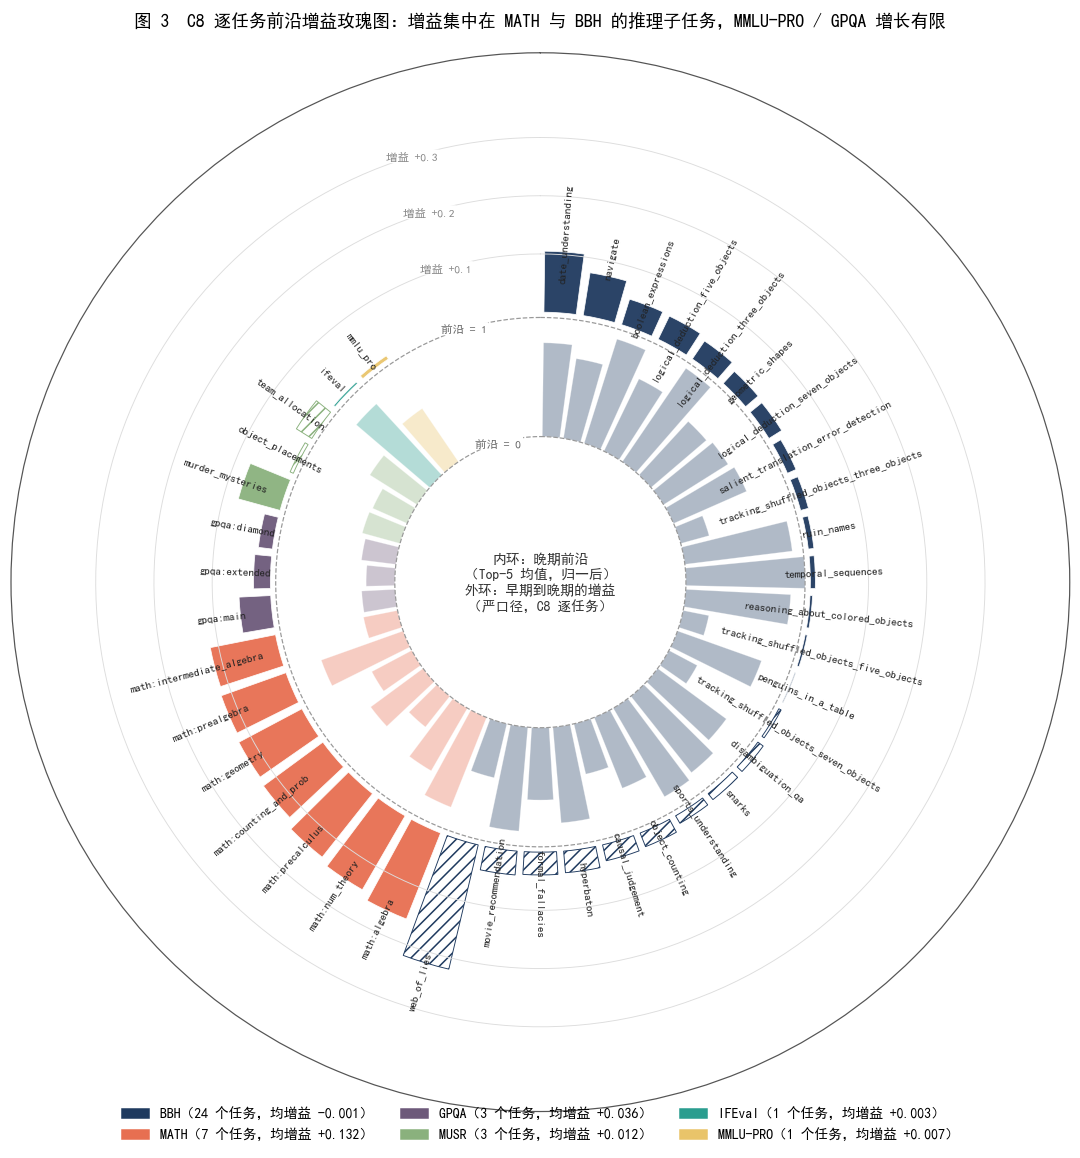

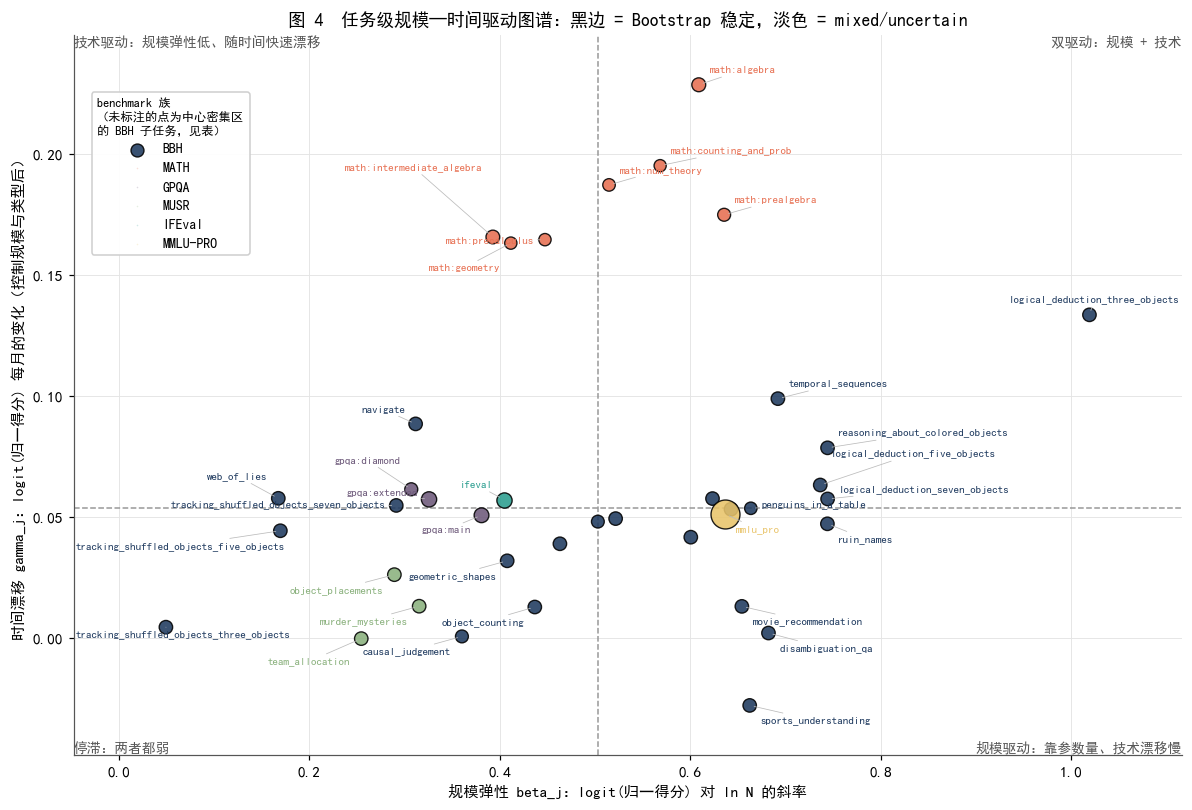

In [22]:
# ============ 2. C8 逐任务聚合分析 ============
tasks_all = sorted(set(c.split('|')[0] for c in C8W.columns if '|' in c))
def family_of(t):
    if t.startswith('leaderboard_bbh'): return 'BBH'
    if t.startswith('leaderboard_gpqa'): return 'GPQA'
    if t.startswith('leaderboard_math'): return 'MATH'
    if t.startswith('leaderboard_musr'): return 'MUSR'
    if t == 'leaderboard_ifeval': return 'IFEval'
    if t == 'leaderboard_mmlu_pro': return 'MMLU-PRO'
    return 'other'
AGG = {'leaderboard', 'leaderboard_bbh', 'leaderboard_gpqa', 'leaderboard_math_hard', 'leaderboard_musr', 'leaderboard_arc_challenge'}
LEAF = [t for t in tasks_all if t not in AGG and family_of(t) != 'other']
def main_metric(t):
    if t == 'leaderboard_ifeval': return 0.5 * (C8W['%s|prompt_level_strict_acc' % t] + C8W['%s|inst_level_strict_acc' % t])
    if t.startswith('leaderboard_math'): return C8W['%s|exact_match' % t]
    if ('%s|acc_norm' % t) in C8W: return C8W['%s|acc_norm' % t]
    return C8W['%s|acc' % t]
RAW = pd.DataFrame({t: main_metric(t) for t in LEAF}); RAW.index = C8W['model_dir']
NS = {t: float(C8CFG['n_samples'].get(t, {}).get('effective', np.nan)) for t in LEAF}
BASE = RAW.quantile(0.02); NORM = ((RAW - BASE) / (1 - BASE)).clip(0, 1)
FAM = {}
for f in FAM_COLORS:
    cols = [t for t in LEAF if family_of(t) == f]; w = np.array([NS[t] for t in cols]); FAM[f] = (NORM[cols].values * w).sum(axis=1) / w.sum()
FAMDF = pd.DataFrame(FAM, index=NORM.index); FAMDF['S_C8'] = 100 * FAMDF[list(FAM_COLORS)].mean(axis=1)
LB = LB.merge(FAMDF[['S_C8']], left_on='model_dir', right_index=True, how='left')
ok = LB['S_C8'].notna()
print('C8 叶子任务 %d 个（BBH %d, GPQA %d, MATH %d, MUSR %d, IFEval 1, MMLU-PRO 1）; 与 C1 匹配 %d 个模型' % (len(LEAF), sum(family_of(t) == 'BBH' for t in LEAF), sum(family_of(t) == 'GPQA' for t in LEAF), sum(family_of(t) == 'MATH' for t in LEAF), sum(family_of(t) == 'MUSR' for t in LEAF), ok.sum()))
print('由子任务重建的综合分 S_C8 与 C1 Average: Pearson %.4f, Spearman %.4f, 平均绝对差 %.2f 分' % (np.corrcoef(LB.loc[ok, 'S'], LB.loc[ok, 'S_C8'])[0, 1], stats.spearmanr(LB.loc[ok, 'S'], LB.loc[ok, 'S_C8'])[0], (LB.loc[ok, 'S'] - LB.loc[ok, 'S_C8']).abs().mean()))
print('经验随机基线 b_j 示例:', {t.replace('leaderboard_', ''): round(float(BASE[t]), 3) for t in ['leaderboard_bbh_boolean_expressions', 'leaderboard_gpqa_diamond', 'leaderboard_mmlu_pro', 'leaderboard_musr_murder_mysteries', 'leaderboard_math_algebra_hard', 'leaderboard_ifeval']})

# 逐任务前沿增益（严口径模型，早期 vs 晚期 Top-5 均值）
meta = LB.set_index('model_dir')[['date_sub', 'tau', 'type', 'open_strict', 'lnN', 'S']]
NM = NORM.join(meta, how='inner'); NM = NM[NM['open_strict']]
early = NM[(NM['date_sub'] >= '2024-06-01') & (NM['date_sub'] < '2024-10-01')]; late = NM[(NM['date_sub'] >= '2024-12-01')]
rows = []
for t in LEAF:
    e5 = early[t].nlargest(5).mean(); l5 = late[t].nlargest(5).mean()
    rows.append({'task': t, 'family': family_of(t), 'n_samples': NS[t], 'baseline_b': float(BASE[t]), 'mean_norm_all': float(NM[t].mean()), 'std_norm_all': float(NM[t].std()), 'frontier_early_top5': e5, 'frontier_late_top5': l5, 'gain': l5 - e5, 'headroom_late': 1 - l5})
TASK = pd.DataFrame(rows)
# 任务级能力生产函数：logit(norm) ~ lnN + tau + chat
for t in LEAF:
    d = NM[[t, 'lnN', 'tau', 'type']].dropna(); d = d[(d[t] > 0.01) & (d[t] < 0.99)]
    X = np.column_stack([np.ones(len(d)), d['lnN'], d['tau'], (d['type'] == 'chat/finetuned').astype(float)]); yv = logit(d[t].values)
    b, *_ = np.linalg.lstsq(X, yv, rcond=None); TASK.loc[TASK.task == t, ['beta_lnN', 'gamma_month', 'delta_chat', 'n_fit']] = [b[1], b[2], b[3], len(d)]
TASK['label'] = TASK['task'].str.replace('leaderboard_', '').str.replace('_hard', '').str.replace('bbh_', '').str.replace('musr_', '').str.replace('math_', 'math:').str.replace('gpqa_', 'gpqa:')

# ---- 创新：任务级 Bootstrap 稳定性 ----
for t in LEAF:
    d = NM[[t, 'lnN', 'tau', 'type']].dropna(); d = d[(d[t] > 0.01) & (d[t] < 0.99)]
    if len(d) < 30: continue
    X = np.column_stack([np.ones(len(d)), d['lnN'], d['tau'], (d['type'] == 'chat/finetuned').astype(float)]); yv = logit(d[t].values)
    bb = []
    for _ in range(N_BOOT_TASK):
        ii = RNG.integers(0, len(d), len(d)); bb.append(np.linalg.lstsq(X[ii], yv[ii], rcond=None)[0])
    bb = np.asarray(bb)
    TASK.loc[TASK.task == t, ['p_beta_pos', 'p_gamma_pos', 'beta_lo', 'beta_hi', 'gamma_lo', 'gamma_hi']] = [
        (bb[:, 1] > 0).mean(), (bb[:, 2] > 0).mean(), *np.percentile(bb[:, 1], [5, 95]), *np.percentile(bb[:, 2], [5, 95])]
TASK['stable_scale'] = TASK['p_beta_pos'].fillna(0) >= 0.90
TASK['stable_tech'] = TASK['p_gamma_pos'].fillna(0) >= 0.90
TASK['driver'] = np.select([TASK.stable_scale & TASK.stable_tech, TASK.stable_scale, TASK.stable_tech], ['双驱动', '规模驱动', '技术驱动'], default='mixed/uncertain')

TASK.to_csv(TAB / 'c8_task_level_analysis.csv', index=False, encoding='utf-8-sig')
print('\n逐任务前沿增益（前 8）:'); display(TASK.sort_values('gain', ascending=False).head(8)[['label', 'family', 'n_samples', 'frontier_early_top5', 'frontier_late_top5', 'gain', 'beta_lnN', 'gamma_month']])
print('族级汇总:'); display(TASK.groupby('family').agg(任务数=('task', 'size'), 平均难度_归一均值=('mean_norm_all', 'mean'), 前沿早期=('frontier_early_top5', 'mean'), 前沿晚期=('frontier_late_top5', 'mean'), 增益=('gain', 'mean'), 规模弹性beta=('beta_lnN', 'mean'), 月漂移gamma=('gamma_month', 'mean')))

# ---- 图 3：逐任务前沿增益的玫瑰图（按族分组；外环 = 增益，内环 = 晚期前沿水平与剩余空间） ----
fam_order = ['BBH', 'MATH', 'GPQA', 'MUSR', 'IFEval', 'MMLU-PRO']; T2 = pd.concat([TASK[TASK.family == f].sort_values('gain', ascending=False) for f in fam_order]).reset_index(drop=True)
n_ = len(T2); slots = n_ + 4; theta = np.linspace(0, 2 * np.pi, slots, endpoint=False)[:n_] + np.pi / slots; width = 2 * np.pi / slots * 0.82; gap_theta = 2 * np.pi * (n_ + 2) / slots   # 留 4 个空槽放刻度说明
fig = plt.figure(figsize=(12.5, 12.5)); ax = fig.add_subplot(111, projection='polar'); ax.set_theta_direction(-1); ax.set_theta_zero_location('N'); ax.grid(False); ax.set_xticks([]); ax.set_yticks([])
r_in, r_mid, r_out = 0.55, 1.0, 1.0
for k, r in T2.iterrows():
    c = FAM_COLORS[r['family']]
    ax.bar(theta[k], r['frontier_late_top5'] * (r_mid - r_in), bottom=r_in, width=width, color=c, alpha=0.35, edgecolor='white', lw=0.5)          # 内环：晚期前沿水平（满格 = 1）
    ax.bar(theta[k], max(r['gain'], 0) * 2.2, bottom=r_mid + 0.02, width=width, color=c, alpha=0.95, edgecolor='white', lw=0.5)                   # 外环：前沿增益（放大 2.2 倍）
    if r['gain'] < 0: ax.bar(theta[k], -r['gain'] * 2.2, bottom=r_mid + 0.02, width=width, color='none', edgecolor=c, hatch='///', lw=0.6)
    ang = np.degrees(theta[k]); rot = (90 - ang) % 360; rot = rot - 180 if 90 < rot < 270 else rot
    ax.text(theta[k], r_mid + 0.04 + abs(r['gain']) * 2.2 + 0.05, r['label'], rotation=rot, rotation_mode='anchor', ha='center', va='center', fontsize=7.2, color='#222222')
for rr, lab in ((r_in, '前沿 = 0'), (r_mid, '前沿 = 1')):
    ax.plot(np.linspace(0, 2 * np.pi, 200), [rr] * 200, color='#999999', lw=0.8, ls='--'); ax.text(gap_theta, rr, lab, fontsize=7.5, color='#666666', ha='center', va='center', bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none'))
for gv in (0.1, 0.2, 0.3):
    ax.plot(np.linspace(0, 2 * np.pi, 200), [r_mid + 0.02 + gv * 2.2] * 200, color='#DDDDDD', lw=0.6); ax.text(gap_theta, r_mid + 0.02 + gv * 2.2, '增益 +%.1f' % gv, fontsize=7.5, color='#888888', ha='center', va='center', bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none'))
ax.set_ylim(0, 2.0)
ax.legend(handles=[Patch(color=FAM_COLORS[f], label='%s（%d 个任务，均增益 %+.3f）' % (f, (TASK.family == f).sum(), TASK.loc[TASK.family == f, 'gain'].mean())) for f in fam_order], loc='lower center', bbox_to_anchor=(0.5, -0.04), ncol=3, frameon=False, fontsize=9)
ax.text(0, 0, '内环：晚期前沿\n（Top-5 均值，归一后）\n外环：早期到晚期的增益\n（严口径，C8 逐任务）', ha='center', va='center', fontsize=9, color='#333333')
ax.set_title('图 3  C8 逐任务前沿增益玫瑰图：增益集中在 MATH 与 BBH 的推理子任务，MMLU-PRO / GPQA 增长有限', fontsize=11.5, pad=18)
savefig('fig03_task_gain_rose.png'); plt.show()

# ---- 图 4：任务级"规模弹性 beta vs 时间漂移 gamma"象限图（气泡 = 样本量，色 = 族） ----
fig, ax = plt.subplots(figsize=(13, 8.5)); bx, gy = TASK['beta_lnN'].median(), TASK['gamma_month'].median()
ax.axvline(bx, color='#999999', lw=1, ls='--'); ax.axhline(gy, color='#999999', lw=1, ls='--')
for f in fam_order:
    d = TASK[TASK.family == f]; st = d['driver'] != 'mixed/uncertain'; ax.scatter(d.loc[~st, 'beta_lnN'], d.loc[~st, 'gamma_month'], s=30 + np.sqrt(d.loc[~st, 'n_samples']) * 3, color=FAM_COLORS[f], alpha=0.30, edgecolor='white', linewidths=0.8, label=f if f not in ['BBH'] else None, zorder=2); ax.scatter(d.loc[st, 'beta_lnN'], d.loc[st, 'gamma_month'], s=30 + np.sqrt(d.loc[st, 'n_samples']) * 3, color=FAM_COLORS[f], alpha=0.88, edgecolor='black', linewidths=0.9, label=f if f == 'BBH' else None, zorder=3)
# 标签：只标注离中心较远的任务与非 BBH 族；中心密集区的 BBH 子任务见表 c8_task_level_analysis.csv
far = (abs(TASK['beta_lnN'] - bx) > 0.16) | (abs(TASK['gamma_month'] - gy) > 0.02); lab_df = TASK[(far | TASK['family'].isin(['IFEval', 'MMLU-PRO', 'GPQA', 'MUSR'])) & (TASK['driver'] != 'mixed/uncertain')]
ax.margins(x=0.10, y=0.08)
def repel_labels(ax, rows, iters=300):                        # 简单的标签排斥：在显示坐标下迭代推开重叠的文本框
    fig_ = ax.figure; fig_.canvas.draw(); rend = fig_.canvas.get_renderer(); texts = []
    for _, r in rows.iterrows():
        right = r['beta_lnN'] >= bx; up = r['gamma_month'] >= gy
        texts.append(ax.annotate(r['label'], (r['beta_lnN'], r['gamma_month']), xytext=(7 if right else -7, 7 if up else -7), textcoords='offset points', fontsize=7.2, color=FAM_COLORS[r['family']], ha='left' if right else 'right', va='bottom' if up else 'top', zorder=4, arrowprops=dict(arrowstyle='-', color='#BBBBBB', lw=0.5, shrinkA=0, shrinkB=3)))
    px = 72.0 / fig_.dpi; axbb = ax.get_window_extent(rend)
    for _ in range(iters):
        moved = False; bbs = [t.get_window_extent(rend) for t in texts]
        for i in range(len(texts)):
            for j in range(i + 1, len(texts)):
                a, b = bbs[i], bbs[j]
                if a.overlaps(b):
                    ov_y = min(a.y1, b.y1) - max(a.y0, b.y0); ov_x = min(a.x1, b.x1) - max(a.x0, b.x0)
                    if ov_y <= ov_x * 0.6:                        # 垂直方向推开更省空间
                        s = 1 if (a.y0 + a.y1) >= (b.y0 + b.y1) else -1; d = (ov_y / 2 + 1.5) * px
                        texts[i].xyann = (texts[i].xyann[0], texts[i].xyann[1] + s * d); texts[j].xyann = (texts[j].xyann[0], texts[j].xyann[1] - s * d)
                    else:
                        s = 1 if (a.x0 + a.x1) >= (b.x0 + b.x1) else -1; d = (ov_x / 2 + 1.5) * px
                        texts[i].xyann = (texts[i].xyann[0] + s * d, texts[i].xyann[1]); texts[j].xyann = (texts[j].xyann[0] - s * d, texts[j].xyann[1])
                    moved = True; bbs = [t.get_window_extent(rend) for t in texts]
        for t in texts:                                          # 不出坐标区
            bb = t.get_window_extent(rend); dx = dy = 0
            if bb.x0 < axbb.x0 + 2: dx = (axbb.x0 + 2 - bb.x0) * px
            if bb.x1 > axbb.x1 - 2: dx = (axbb.x1 - 2 - bb.x1) * px
            if bb.y0 < axbb.y0 + 2: dy = (axbb.y0 + 2 - bb.y0) * px
            if bb.y1 > axbb.y1 - 2: dy = (axbb.y1 - 2 - bb.y1) * px
            if dx or dy: t.xyann = (t.xyann[0] + dx, t.xyann[1] + dy); moved = True
        if not moved: break
repel_labels(ax, lab_df)
xl, yl = ax.get_xlim(), ax.get_ylim()
for (x_, y_, txt) in ((xl[1], yl[1], '双驱动：规模 + 技术'), (xl[0], yl[1], '技术驱动：规模弹性低、随时间快速漂移'), (xl[1], yl[0], '规模驱动：靠参数量、技术漂移慢'), (xl[0], yl[0], '停滞：两者都弱')):
    ax.text(x_, y_, txt, ha='right' if x_ == xl[1] else 'left', va='top' if y_ == yl[1] else 'bottom', fontsize=9, color='#555555', style='italic')
ax.set_xlabel('规模弹性 beta_j：logit(归一得分) 对 ln N 的斜率'); ax.set_ylabel('时间漂移 gamma_j：logit(归一得分) 每月的变化（控制规模与类型后）')
ax.legend(frameon=True, fontsize=9, loc='upper left', bbox_to_anchor=(0.01, 0.93), title='benchmark 族\n（未标注的点为中心密集区\n的 BBH 子任务，见表）', title_fontsize=8, facecolor='white', framealpha=0.95); ax.set_title('图 4  任务级规模—时间驱动图谱：黑边 = Bootstrap 稳定，淡色 = mixed/uncertain', fontsize=11.5)
savefig('fig04_task_scale_vs_time_quadrant.png'); plt.show()

## 3. 能力生产函数：从“时间趋势”升级为双时间轴识别

### 3.1 原版前沿模型继续保留
对 C1 严口径、分类型模型拟合 q=0.9 前沿分位面：
$$Q_{0.9}(y_i)=\beta_0+\beta_1\ln N_i+\beta_2(\ln N_i)^2+\gamma\tau_i.$$
它仍用于参数需求半衰期、等能力线、Shapley 分解，是与原版完全可比的 baseline。

### 3.2 创新：训练算力 q90 + Delay-Aware Dual-Time Frontier
对 C1 与 C4 唯一名称匹配的模型，训练算力作为规模主变量。比较三个模型：

- **B-OLS（原版）**：$E[y]=\beta_0+\beta_C\ln C+\gamma t^{pub}+\delta I[chat]$；
- **B-Q90**：$Q_{0.9}(y)=\beta_0+\beta_C\ln C+\gamma t^{pub}+\delta I[chat]$；
- **B-DATF（创新）**：$Q_{0.9}(y)=\beta_0+\beta_C\ln C+\gamma_{tech}t^{pub}+\rho d+\delta I[chat]$。

其中 $d=t^{submit}-t^{pub}$。由于提交时间可写成“发布日期 + 延迟”，DATF 的目的是把 **技术年代** 与 **进入排行榜的滞后** 拆开，而不是把后者强行解释成算法进步。最终哪一个模型进入预测，不由主观指定，而由第 6 节 rolling-origin 样本外误差决定。

### 3.3 规模—非规模贡献
原版 Shapley 与同规模 Top-5 分解全部保留；新增的 DATF 系数只作为更严格的技术通道候选。任何“因果”措辞都限定为 **控制观测规模与类型后的统计分解**，不把不可观测的架构、训练数据、后训练技巧完全等同于时间变量。


pretrained（严口径 n=241，corr(lnN, tau)=-0.29）: 前沿分位回归 q=0.9: b1=-1.535 b2=0.0450 gamma=0.0231/月 [95% CI 0.0022, 0.0486]; 参考规模 3B 处 beta_N=0.427 -> 参数需求半衰期 12.8 月, 非规模进步 = 每年参数 x1.91 [1.07, 3.90]; OLS gamma=0.0332
chat/finetuned（严口径 n=2257，corr(lnN, tau)=-0.12）: 前沿分位回归 q=0.9: b1=2.043 b2=-0.0353 gamma=0.0637/月 [95% CI 0.0566, 0.0744]; 参考规模 8B 处 beta_N=0.434 -> 参数需求半衰期 4.7 月, 非规模进步 = 每年参数 x5.81 [4.62, 8.10]; OLS gamma=0.0597

不同参考规模处的半衰期与年等价参数倍数:


,类型,参考规模,beta_N,参数需求半衰期(月),年等价参数倍数
0,pretrained,1B,0.3304,9.9281,2.3113
1,pretrained,8B,0.5176,15.5530,1.7071
2,pretrained,70B,0.7129,21.4203,1.4745
3,chat/finetuned,1B,0.5812,6.3266,3.7238
4,chat/finetuned,8B,0.4346,4.7304,5.8030
5,chat/finetuned,70B,0.2816,3.0654,15.0808



Shapley 分解（严口径，q=0.9 前沿面；占比截断到 [0,1]，规模贡献为负时非规模占比记为 100%）:


,类型,口径,起点,终点,S0,S1,实际变化,规模贡献,非规模贡献,残差,非规模占比,占比 95% CI
0,pretrained,记录保持者,"Yi-1.5-34B-32K (34B, 26.7)","Qwen2.5-32B (33B, 38.0)",26.7279,38.0080,11.2801,-0.7434,4.9389,7.0845,1.0000,"[0.91, 1.00]"
1,chat/finetuned,记录保持者,"Meta-LLama-3-Cat-Smaug (71B, 38.7)","CalmeRys-78B-Orpo-v0.1 (78B, 51.2)",38.6961,51.2313,12.5352,0.6804,13.4632,-1.6084,0.9519,"[0.93, 0.96]"



同规模口径：各参数量区间内 Top-5 均分的首季 -> 末季变化（纯非规模进步）:


,类型,规模区间,首季 Top-5 均分,末季 Top-5 均分,同规模增益,n 首季/末季
0,pretrained,0.5-3B,11.9263,15.3728,3.4465,5/5
1,pretrained,3-10B,20.9812,21.5427,0.5615,5/5
2,pretrained,10-30B,22.4088,27.8632,5.4544,5/5
3,pretrained,30-200B,26.2353,NaN,NaN,5/0
4,chat/finetuned,0.5-3B,15.1926,23.2494,8.0568,5/5
5,chat/finetuned,3-10B,31.4152,38.5739,7.1587,5/5
6,chat/finetuned,10-30B,33.3967,44.4050,11.0082,5/5
7,chat/finetuned,30-200B,44.3772,47.1062,2.7290,5/5



与 Epoch AI 训练算力唯一匹配的排行榜模型: 83 个（pretrained 60, chat 23）；exact-tail 48 / normalized-unique 35
发布→提交延迟: 中位 4.2 月，IQR [0.9, 11.2] 月；负延迟 1 个（保留并在稳健性中检查）

算力—技术模型候选（最终由 rolling-origin 回测决定）:


,模型,beta_C,gamma_tech/月,rho_lag,等效算力年倍数,可用于预测
0,B-OLS 原版,0.1779,0.0245,NaN,5.2142,True
1,B-Q90 前沿分位,0.1286,0.0325,NaN,20.7512,True
2,B-DATF 双时间轴,0.1431,0.0607,0.0297,162.1443,True


B-OLS R2 = 0.514；DATF 中 rho_lag = 0.0297 / 月，若 rho_lag 明显大于 0，说明提交时间趋势含有扩散/评测滞后成分。


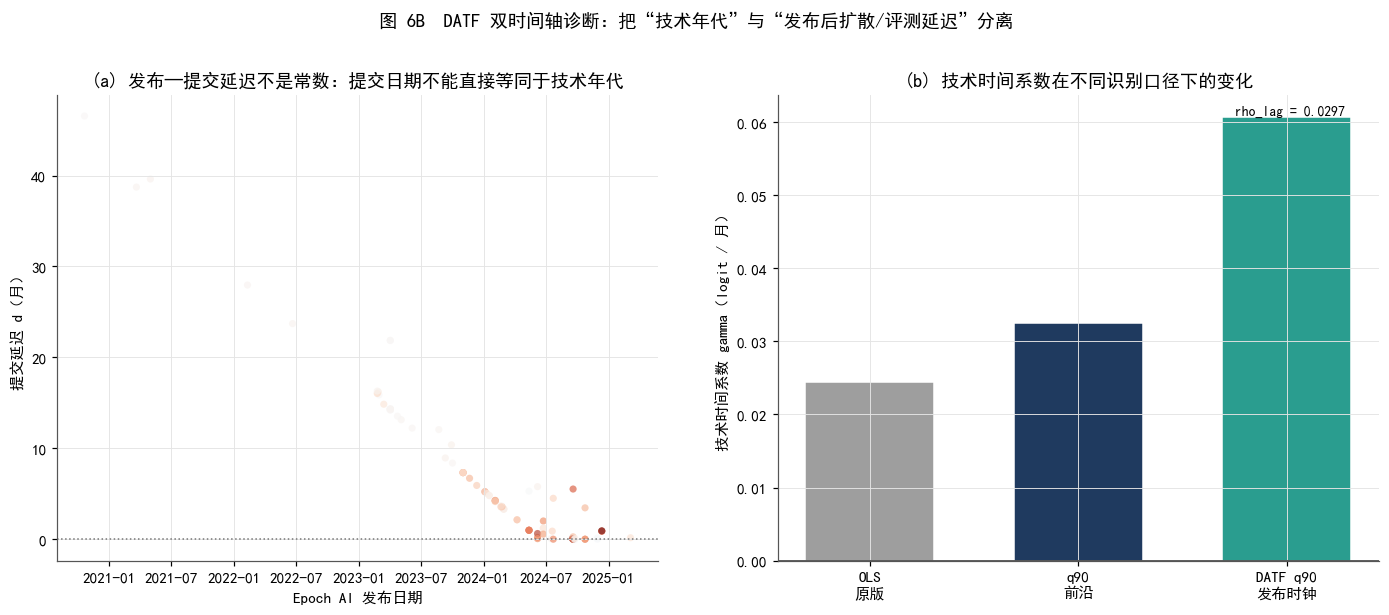

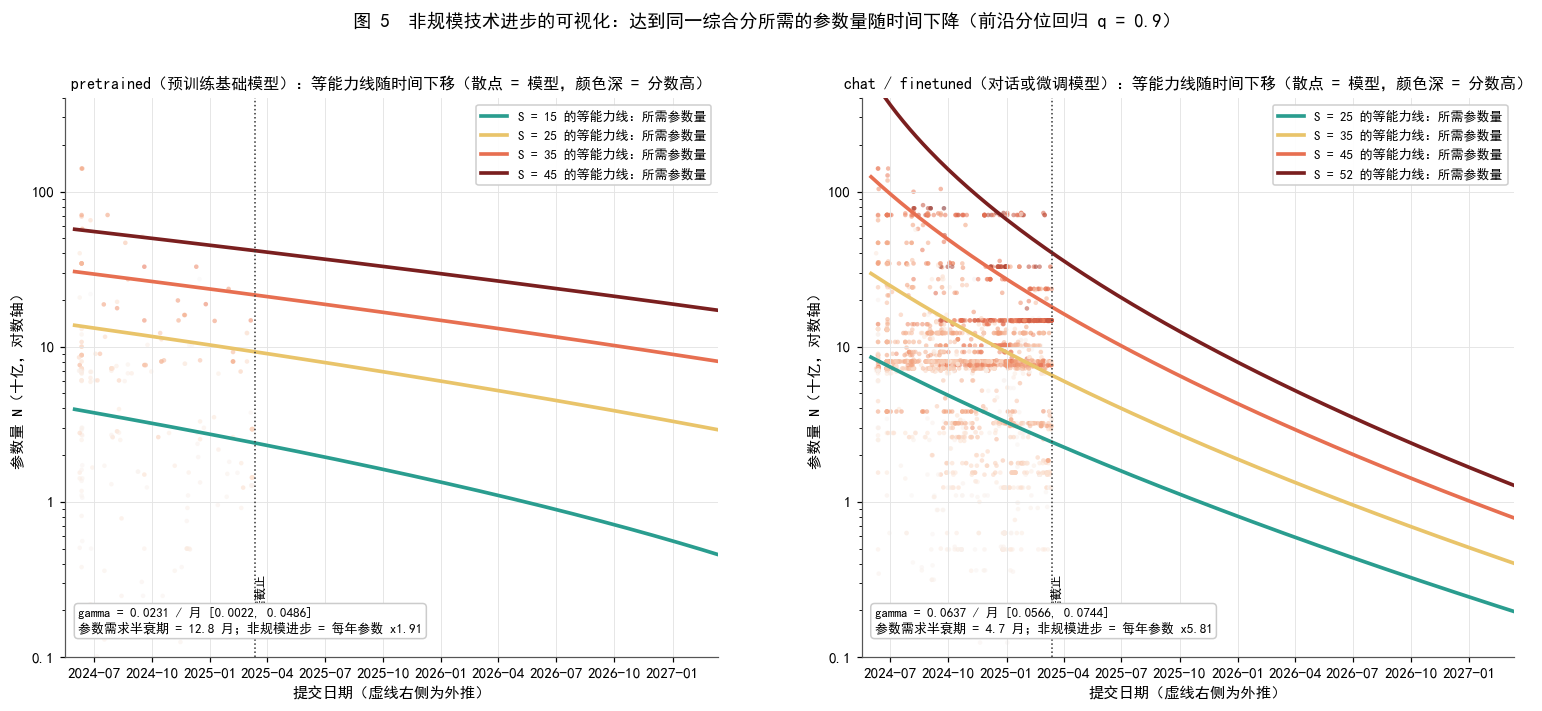

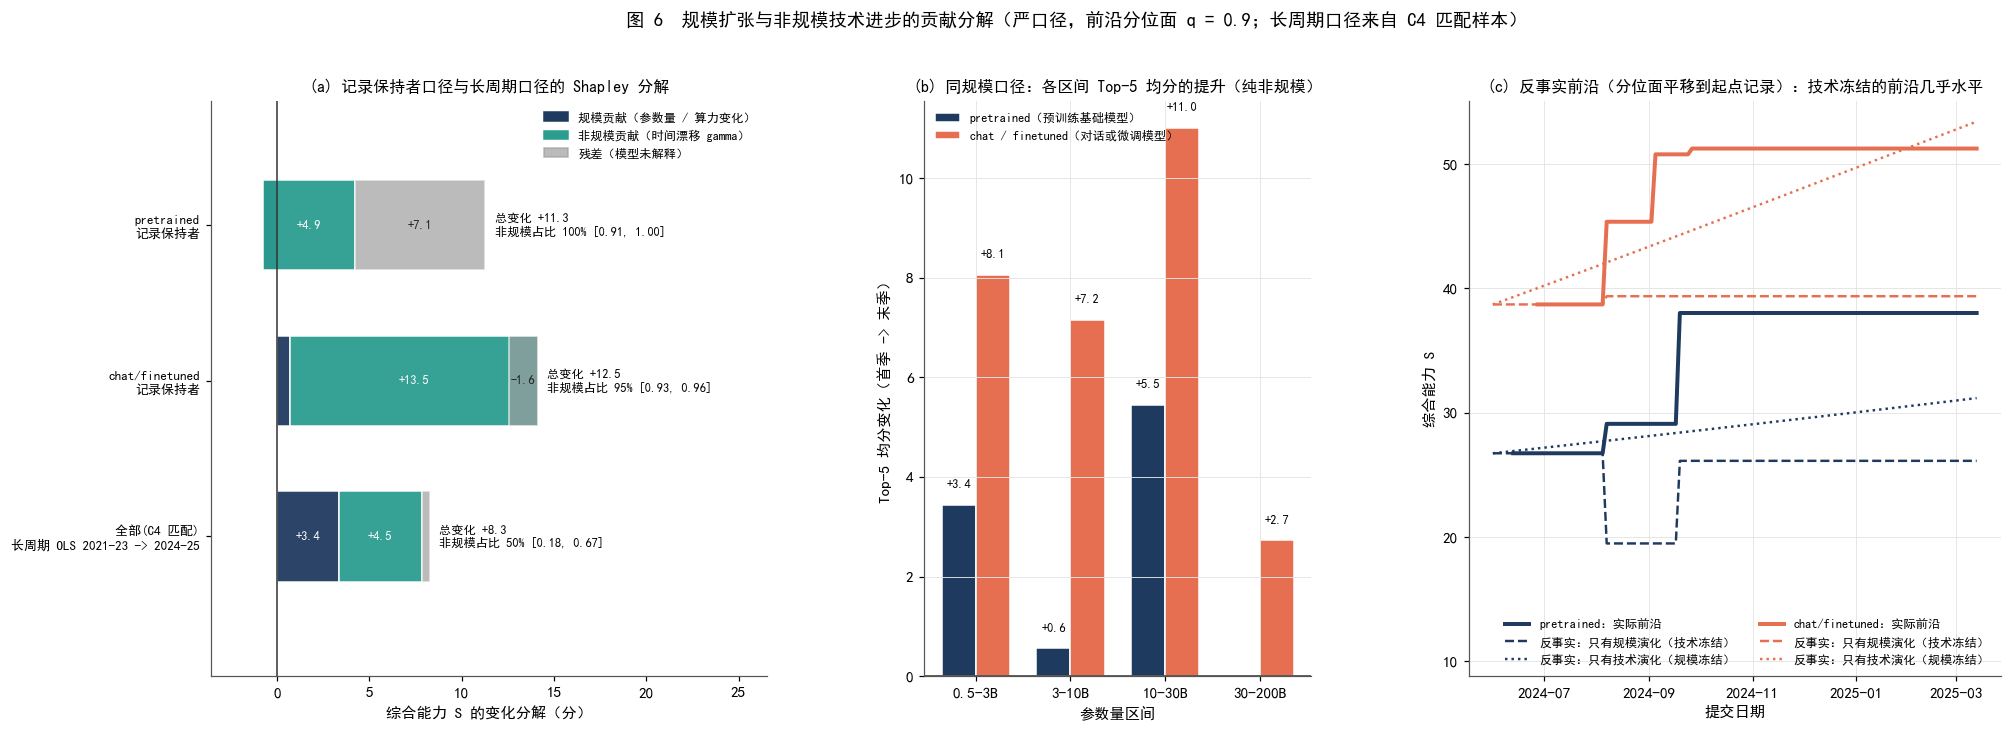

In [35]:
# ============ 3. 能力生产函数、分位数回归与分解 ============
# ============ 稳定版分位数回归 ============
from statsmodels.regression.quantile_regression import QuantReg
import warnings

def quantreg(X, y, q=0.9):
    """
    稳定分位数回归。
    使用 statsmodels QuantReg，避免旧版 scipy.linprog 在
    大样本 + Bootstrap 下出现 Numerical difficulties。

    返回系数仍然对应原始 X，不改变后续公式与参数含义。
    """
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float)

    # 1. 清除异常值
    ok = np.isfinite(y) & np.all(np.isfinite(X), axis=1)
    X = X[ok]
    y = y[ok]

    n, p = X.shape

    if n <= p + 2:
        raise RuntimeError(
            f'分位数回归有效样本过少: n={n}, p={p}'
        )

    # 2. 对除截距以外的变量标准化，改善数值条件
    mu = np.zeros(p)
    sd = np.ones(p)

    active = [0]
    Z_cols = [X[:, 0]]

    for j in range(1, p):
        mu[j] = np.mean(X[:, j])
        sj = np.std(X[:, j])

        # Bootstrap 后某些变量偶尔可能变成常数
        if sj > 1e-10:
            sd[j] = sj
            Z_cols.append((X[:, j] - mu[j]) / sd[j])
            active.append(j)

    Z = np.column_stack(Z_cols)

    # 3. Quantile Regression
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")

        model = QuantReg(y, Z)

        result = model.fit(
            q=q,
            max_iter=5000,
            p_tol=1e-7
        )

    beta_std = np.asarray(result.params, dtype=float)

    if not np.all(np.isfinite(beta_std)):
        raise RuntimeError('分位数回归产生非有限系数')

    # 4. 将标准化后的系数恢复到原变量尺度
    beta = np.zeros(p, dtype=float)

    beta[0] = beta_std[0]

    for k, j in enumerate(active[1:], start=1):
        beta[j] = beta_std[k] / sd[j]
        beta[0] -= beta_std[k] * mu[j] / sd[j]

    return beta
    #r = linprog(c, A_eq=A, b_eq=y, bounds=bounds, method='highs'); return r.x[:p]
def design(lnN, tau_): return np.column_stack([np.ones(len(lnN)), lnN, lnN ** 2, tau_])
def f_pred(b, N, tau_): lnN = np.log(np.asarray(N, float)); return 100 * expit(b[0] + b[1] * lnN + b[2] * lnN ** 2 + b[3] * np.asarray(tau_, float))

Q_FRONT = 0.9; FIT = {}; BOOT = {}
for g in ('pretrained', 'chat/finetuned'):
    d = LB[(LB['type'] == g) & LB['open_strict']]; X = design(d['lnN'].values, d['tau'].values); yv = d['y'].values
    b = quantreg(X, yv, Q_FRONT); bo = np.array([quantreg(X[idx], yv[idx], Q_FRONT) for idx in (RNG.integers(0, len(d), len(d)) for _ in range(150))])
    ols, *_ = np.linalg.lstsq(X, yv, rcond=None); FIT[g] = {'b': b, 'ols': ols, 'n': len(d), 'corr_lnN_tau': float(np.corrcoef(d['lnN'], d['tau'])[0, 1])}; BOOT[g] = bo
    Nref = float(np.exp(np.median(d['lnN']))); bN = b[1] + 2 * b[2] * np.log(Nref); bN_bo = bo[:, 1] + 2 * bo[:, 2] * np.log(Nref)
    FIT[g].update({'N_ref': Nref, 'beta_N': bN, 'gamma': b[3], 'half_life_month': np.log(2) * bN / b[3] if b[3] > 0 else np.inf, 'annual_param_multiplier': float(np.exp(12 * b[3] / bN)),
                   'gamma_ci': np.percentile(bo[:, 3], [2.5, 97.5]).tolist(), 'mult_ci': np.percentile(np.exp(12 * bo[:, 3] / bN_bo), [2.5, 97.5]).tolist()})
    print('%s（严口径 n=%d，corr(lnN, tau)=%.2f）: 前沿分位回归 q=%.1f: b1=%.3f b2=%.4f gamma=%.4f/月 [95%% CI %.4f, %.4f]; 参考规模 %.0fB 处 beta_N=%.3f -> 参数需求半衰期 %.1f 月, 非规模进步 = 每年参数 x%.2f [%.2f, %.2f]; OLS gamma=%.4f'
          % (g, len(d), FIT[g]['corr_lnN_tau'], Q_FRONT, b[1], b[2], b[3], *FIT[g]['gamma_ci'], Nref / 1e9, bN, FIT[g]['half_life_month'], FIT[g]['annual_param_multiplier'], *FIT[g]['mult_ci'], ols[3]))

# 参数需求半衰期与年等价参数倍数在不同参考规模处的取值（beta_N 随规模变化）
rows = []
for g in FIT:
    b = FIT[g]['b']
    for Nr in (1e9, 8e9, 70e9):
        bN = b[1] + 2 * b[2] * np.log(Nr); rows.append({'类型': g, '参考规模': '%gB' % (Nr / 1e9), 'beta_N': bN, '参数需求半衰期(月)': np.log(2) * bN / b[3] if b[3] > 0 and bN > 0 else np.inf, '年等价参数倍数': float(np.exp(12 * b[3] / bN)) if bN > 0 else np.nan})
HL = pd.DataFrame(rows); print('\n不同参考规模处的半衰期与年等价参数倍数:'); display(HL); HL.to_csv(TAB / 'half_life_by_scale.csv', index=False, encoding='utf-8-sig')

# Shapley 分解（三种口径）
def shapley(b, N0, t0, N1, t1):
    f = lambda N, t: float(f_pred(b, [N], [t])[0])
    scale = 0.5 * ((f(N1, t0) - f(N0, t0)) + (f(N1, t1) - f(N0, t1))); tech = 0.5 * ((f(N0, t1) - f(N0, t0)) + (f(N1, t1) - f(N1, t0)))
    return scale, tech, f(N0, t0), f(N1, t1)
def top_group(df, lo, hi, q=0.9):
    d = df[(df['tau'] >= lo) & (df['tau'] < hi)]; thr = d['S'].quantile(q); top = d[d['S'] >= thr]; return float(np.exp(top['lnN'].median())), float(top['tau'].mean()), float(top['S'].mean()), len(top)
DEC = []
for g in ('pretrained', 'chat/finetuned'):
    d = LB[(LB['type'] == g) & LB['open_strict']]; e = ENV[g]
    # (i) 记录保持者口径
    N0, t0, N1, t1 = e['N_B'].iloc[0] * 1e9, e['tau'].iloc[0], e['N_B'].iloc[-1] * 1e9, float(LB['tau'].max())
    sc, te, f0, f1 = shapley(FIT[g]['b'], N0, t0, N1, t1); dF = e['S'].iloc[-1] - e['S'].iloc[0]; bo = np.array([shapley(bb, N0, t0, N1, t1)[:2] for bb in BOOT[g]])
    DEC.append({'类型': g, '口径': '记录保持者', '起点': '%s (%.0fB, %.1f)' % (e['Model'].iloc[0].split('/')[-1][:22], N0 / 1e9, e['S'].iloc[0]), '终点': '%s (%.0fB, %.1f)' % (e['Model'].iloc[-1].split('/')[-1][:22], N1 / 1e9, e['S'].iloc[-1]), 'S0': e['S'].iloc[0], 'S1': e['S'].iloc[-1],
                '实际变化': dF, '规模贡献': sc, '非规模贡献': te, '残差': dF - (sc + te), '非规模占比': np.clip(te / (sc + te), 0, 1) if (sc + te) > 0 else np.nan, '占比 95% CI': '[%.2f, %.2f]' % tuple(np.clip(np.percentile(bo[:, 1] / (bo[:, 0] + bo[:, 1]), [2.5, 97.5]), 0, 1))})
DECDF = pd.DataFrame(DEC); print('\nShapley 分解（严口径，q=0.9 前沿面；占比截断到 [0,1]，规模贡献为负时非规模占比记为 100%）:'); display(DECDF)
# (ii) 同规模口径（无模型）：各参数量区间内 Top-5 均分从首季到末季的变化，全部是非规模进步
BANDS = [(0.5, 3, '0.5-3B'), (3, 10, '3-10B'), (10, 30, '10-30B'), (30, 200, '30-200B')]; rows = []
for g in ('pretrained', 'chat/finetuned'):
    d = LB[(LB['type'] == g) & LB['open_strict']]
    for lo, hi, lab in BANDS:
        e0 = d[(d['N_B'] >= lo) & (d['N_B'] < hi) & (d['tau'] < 3)]['S'].nlargest(5); e1 = d[(d['N_B'] >= lo) & (d['N_B'] < hi) & (d['tau'] >= LB['tau'].max() - 3)]['S'].nlargest(5)
        rows.append({'类型': g, '规模区间': lab, '首季 Top-5 均分': e0.mean(), '末季 Top-5 均分': e1.mean(), '同规模增益': e1.mean() - e0.mean(), 'n 首季/末季': '%d/%d' % (len(e0), len(e1))})
BAND = pd.DataFrame(rows); print('\n同规模口径：各参数量区间内 Top-5 均分的首季 -> 末季变化（纯非规模进步）:'); display(BAND); BAND.to_csv(TAB / 'same_scale_gains.csv', index=False, encoding='utf-8-sig')


# ---- C1 x C4：唯一规范化名称匹配 + 匹配审计 ----
def norm_name(s):
    s = str(s).lower().split('/')[-1]; s = re.sub(r'[\s_\-\.]', '', s)
    return s.replace('instruct', 'it').replace('chat', '')
C4L = C4[C4['Domain'].astype(str).str.contains('Language')].copy(); C4L['key'] = C4L['Model'].map(norm_name)
C4L['C'] = pd.to_numeric(C4L['Training compute (FLOP)'], errors='coerce'); C4L['date_pub4'] = pd.to_datetime(C4L['Publication date'], errors='coerce')
C4L['D_tokens'] = pd.to_numeric(C4L['Training dataset size (total)'], errors='coerce'); C4L['open_w'] = C4L['Open model weights?']
key_n = C4L.groupby('key').size(); unique_keys = key_n[key_n == 1].index
C4U = C4L[C4L['key'].isin(unique_keys)].dropna(subset=['C']).copy().rename(columns={'Model': 'Model_C4'})
LB['key'] = LB['Model'].map(norm_name)
MC = LB.merge(C4U[['key', 'Model_C4', 'C', 'date_pub4', 'D_tokens', 'open_w', 'Organization']], on='key', how='inner')
MC['match_method'] = np.where(MC['Model'].str.lower().str.split('/').str[-1] == MC['Model_C4'].str.lower().str.split('/').str[-1], 'exact_tail', 'normalized_unique')
MC['tau_pub'] = (MC['date_pub4'] - T0).dt.days / 30.4375; MC['lag_month'] = (MC['date_sub'] - MC['date_pub4']).dt.days / 30.4375
MC = MC.dropna(subset=['tau_pub', 'lag_month', 'C']).copy(); MC['lnC_c'] = np.log(MC['C']) - np.log(MC['C']).median(); MC['chat'] = (MC['type'] == 'chat/finetuned').astype(float)
print('\n与 Epoch AI 训练算力唯一匹配的排行榜模型: %d 个（pretrained %d, chat %d）；exact-tail %d / normalized-unique %d' % (len(MC), (MC.type == 'pretrained').sum(), (MC.type == 'chat/finetuned').sum(), (MC.match_method == 'exact_tail').sum(), (MC.match_method == 'normalized_unique').sum()))
print('发布→提交延迟: 中位 %.1f 月，IQR [%.1f, %.1f] 月；负延迟 %d 个（保留并在稳健性中检查）' % (MC.lag_month.median(), MC.lag_month.quantile(.25), MC.lag_month.quantile(.75), (MC.lag_month < 0).sum()))

# 三个竞争模型：原 OLS / q90 / 双时间轴 q90
Xc = np.column_stack([np.ones(len(MC)), MC['lnC_c'], MC['tau_pub'], MC['chat']]); yc = MC['y'].values
bc_ols, *_ = np.linalg.lstsq(Xc, yc, rcond=None)
bo_c_ols = np.array([np.linalg.lstsq(Xc[ii], yc[ii], rcond=None)[0] for ii in (RNG.integers(0, len(MC), len(MC)) for _ in range(N_BOOT))])
bc_q = quantreg(Xc, yc, 0.9); bo_c_q = np.array([quantreg(Xc[ii], yc[ii], 0.9) for ii in (RNG.integers(0, len(MC), len(MC)) for _ in range(N_BOOT))])
Xd = np.column_stack([np.ones(len(MC)), MC['lnC_c'], MC['tau_pub'], MC['lag_month'], MC['chat']])
bd_q = quantreg(Xd, yc, 0.9); bo_dual = np.array([quantreg(Xd[ii], yc[ii], 0.9) for ii in (RNG.integers(0, len(MC), len(MC)) for _ in range(N_BOOT))])
R2c = 1 - ((yc - Xc @ bc_ols) ** 2).sum() / ((yc - yc.mean()) ** 2).sum()

def eq_compute_mult(beta, gamma): return float(np.exp(12 * gamma / beta)) if beta > 0 and np.isfinite(beta) else np.nan
MODEL_C = pd.DataFrame([
    {'模型': 'B-OLS 原版', 'beta_C': bc_ols[1], 'gamma_tech/月': bc_ols[2], 'rho_lag': np.nan, '等效算力年倍数': eq_compute_mult(bc_ols[1], bc_ols[2]), '可用于预测': bc_ols[1] > 0},
    {'模型': 'B-Q90 前沿分位', 'beta_C': bc_q[1], 'gamma_tech/月': bc_q[2], 'rho_lag': np.nan, '等效算力年倍数': eq_compute_mult(bc_q[1], bc_q[2]), '可用于预测': bc_q[1] > 0},
    {'模型': 'B-DATF 双时间轴', 'beta_C': bd_q[1], 'gamma_tech/月': bd_q[2], 'rho_lag': bd_q[3], '等效算力年倍数': eq_compute_mult(bd_q[1], bd_q[2]), '可用于预测': bd_q[1] > 0}
])
print('\n算力—技术模型候选（最终由 rolling-origin 回测决定）:'); display(MODEL_C)
print('B-OLS R2 = %.3f；DATF 中 rho_lag = %.4f / 月，若 rho_lag 明显大于 0，说明提交时间趋势含有扩散/评测滞后成分。' % (R2c, bd_q[3]))
MODEL_C.to_csv(TAB / 'compute_tech_model_candidates.csv', index=False, encoding='utf-8-sig')
MC.to_csv(TAB / 'leaderboard_matched_epoch_compute.csv', index=False, encoding='utf-8-sig')

# 仍保留原版“等效算力进步”口径，供前三问接口和消融对照
mult_C = eq_compute_mult(bc_ols[1], bc_ols[2]); mult_C_ci = np.percentile(np.exp(12 * bo_c_ols[:, 2] / bo_c_ols[:, 1]), [2.5, 97.5])
#a_exp = Q2['compute_optimal']['a']
# 从问题二最终版 classic_law 自动推导 compute-optimal 参数指数
alpha_q2 = float(Q2['classic_law']['alpha'])
beta_q2  = float(Q2['classic_law']['beta'])

a_exp = beta_q2 / (alpha_q2 + beta_q2)
ALG = {'mult_C_epoch': float(mult_C), 'mult_C_ci': mult_C_ci.tolist(), 'mult_N_pre': FIT['pretrained']['annual_param_multiplier'], 'mult_N_chat': FIT['chat/finetuned']['annual_param_multiplier'], 'a_exp': float(a_exp)}

# 长周期 OLS 分解（与原版可比）
early_ = MC[MC['date_pub4'] < '2024-01-01']; late_ = MC[MC['date_pub4'] >= '2024-01-01']
dy_ = late_['y'].mean() - early_['y'].mean(); dC_ = np.log(late_['C']).mean() - np.log(early_['C']).mean(); dt_ = late_['tau_pub'].mean() - early_['tau_pub'].mean(); dchat_ = late_['chat'].mean() - early_['chat'].mean()
sc_C, te_C, ch_C = bc_ols[1] * dC_, bc_ols[2] * dt_, bc_ols[3] * dchat_; bo_sh = (bo_c_ols[:, 2] * dt_) / (bo_c_ols[:, 1] * dC_ + bo_c_ols[:, 2] * dt_)
DECDF = pd.concat([DECDF, pd.DataFrame([{'类型': '全部(C4 匹配)', '口径': '长周期 OLS 2021-23 -> 2024-25', '起点': '%d 个模型' % len(early_), '终点': '%d 个模型' % len(late_), 'S0': 100 * expit(early_['y'].mean()), 'S1': 100 * expit(late_['y'].mean()), '实际变化': 100 * expit(late_['y'].mean()) - 100 * expit(early_['y'].mean()), '规模贡献': 100 * (expit(early_['y'].mean() + sc_C) - expit(early_['y'].mean())), '非规模贡献': 100 * (expit(early_['y'].mean() + sc_C + te_C) - expit(early_['y'].mean() + sc_C)), '残差': 100 * (expit(late_['y'].mean()) - expit(early_['y'].mean() + sc_C + te_C)), '非规模占比': float(np.clip(te_C / (sc_C + te_C), 0, 1)), '占比 95% CI': '[%.2f, %.2f]' % tuple(np.clip(np.percentile(bo_sh, [2.5, 97.5]), 0, 1))}])], ignore_index=True)
DECDF.to_csv(TAB / 'shapley_decomposition.csv', index=False, encoding='utf-8-sig')
json.dump({'quantile_fits': {g: {k: (v.tolist() if isinstance(v, np.ndarray) else v) for k, v in FIT[g].items()} for g in FIT}, 'compute_candidates': MODEL_C.to_dict(orient='records'), 'ols_coef': bc_ols.tolist(), 'q90_coef': bc_q.tolist(), 'dual_q90_coef': bd_q.tolist(), 'R2_ols': float(R2c), 'ALG_baseline': ALG}, open(TAB / 'production_function_fits.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=1)

# ---- 新图 6B：双时间轴诊断 ----
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.5))
ax = axes[0]; ax.scatter(MC['date_pub4'], MC['lag_month'], s=22, c=MC['S'], cmap=CMAP_HEAT, alpha=0.7, edgecolor='none'); ax.axhline(0, color='#777777', lw=1, ls=':')
ax.set_xlabel('Epoch AI 发布日期'); ax.set_ylabel('提交延迟 d（月）'); ax.set_title('(a) 发布—提交延迟不是常数：提交日期不能直接等同于技术年代')
ax = axes[1]; vals = [bc_ols[2], bc_q[2], bd_q[2]]; labs = ['OLS\n原版', 'q90\n前沿', 'DATF q90\n发布时钟']
ax.bar(np.arange(3), vals, width=0.62, color=[C_GREY, C_NAVY, C_TEAL], edgecolor='white'); ax.axhline(0, color='#333333', lw=1); ax.set_xticks(np.arange(3)); ax.set_xticklabels(labs); ax.set_ylabel('技术时间系数 gamma（logit / 月）')
ax.text(2, bd_q[2], '\n rho_lag = %.4f' % bd_q[3], ha='center', va='bottom' if bd_q[2] >= 0 else 'top', fontsize=9)
ax.set_title('(b) 技术时间系数在不同识别口径下的变化')
fig.suptitle('图 6B  DATF 双时间轴诊断：把“技术年代”与“发布后扩散/评测延迟”分离', fontsize=12, y=1.02)
savefig('fig06b_dual_time_diagnostic.png'); plt.show()

# ---- 图 5：等能力线的左移（达到同一分数所需参数量随时间下降）+ 参数需求半衰期 ----
fig = plt.figure(figsize=(17, 6.6)); gs = gridspec.GridSpec(1, 2, width_ratios=[1, 1], wspace=0.22)
tt = np.linspace(0, LB['tau'].max() + 24, 200); dates = [T0 + pd.Timedelta(days=30.4375 * v) for v in tt]
for ax, g in zip((fig.add_subplot(gs[0]), fig.add_subplot(gs[1])), ('pretrained', 'chat/finetuned')):
    d = LB[(LB['type'] == g) & LB['open_strict']]; b = FIT[g]['b']
    ax.scatter(d['date_sub'], d['N_B'], s=9, c=d['S'], cmap=CMAP_HEAT, alpha=0.55, edgecolor='none', vmin=0, vmax=52)
    levels = [15, 25, 35, 45] if g == 'pretrained' else [25, 35, 45, 52]
    for lv, c in zip(levels, [C_TEAL, C_GOLD, C_CORAL, C_RUST]):
        ylv = logit(lv / 100); Nreq = []
        for t_ in tt:                                             # 解 b0 + b1 x + b2 x^2 + gamma t = ylv 的 x（取物理解）
            A2, B2, C2_ = b[2], b[1], b[0] + b[3] * t_ - ylv; disc = B2 ** 2 - 4 * A2 * C2_
            if abs(A2) < 1e-9: x = -C2_ / B2
            else:
                if disc < 0: Nreq.append(np.nan); continue
                x1, x2 = (-B2 - np.sqrt(disc)) / (2 * A2), (-B2 + np.sqrt(disc)) / (2 * A2); x = min([v for v in (x1, x2) if 15 < v < 30], default=np.nan)
            Nreq.append(np.exp(x) / 1e9 if np.isfinite(x) else np.nan)
        ax.plot(dates, Nreq, color=c, lw=2.4, label='S = %d 的等能力线：所需参数量' % lv)
    ax.axvline(LB['date_sub'].max(), color='#333333', lw=1, ls=':'); ax.text(LB['date_sub'].max(), 0.15, ' 数据截止 ', fontsize=8, rotation=90, va='bottom')
    ax.set_yscale('log'); ax.yaxis.set_major_formatter(plain); ax.set_ylim(0.1, 400); ax.set_xlim(T0 - pd.Timedelta(days=15), dates[-1]); ax.xaxis.set_major_formatter(mpl.dates.DateFormatter('%Y-%m'))
    ax.set_xlabel('提交日期（虚线右侧为外推）'); ax.set_ylabel('参数量 N（十亿，对数轴）'); ax.legend(frameon=True, fontsize=8.5, loc='upper right', facecolor='white', framealpha=0.95)
    ax.text(0.02, 0.04, 'gamma = %.4f / 月 [%.4f, %.4f]\n参数需求半衰期 = %.1f 月；非规模进步 = 每年参数 x%.2f' % (FIT[g]['gamma'], *FIT[g]['gamma_ci'], FIT[g]['half_life_month'], FIT[g]['annual_param_multiplier']), transform=ax.transAxes, fontsize=8.5, va='bottom', bbox=dict(boxstyle='round', fc='white', ec='#CCCCCC'))
    ax.set_title('%s：等能力线随时间下移（散点 = 模型，颜色深 = 分数高）' % NAME_TYPE[g], fontsize=10.5)
fig.suptitle('图 5  非规模技术进步的可视化：达到同一综合分所需的参数量随时间下降（前沿分位回归 q = 0.9）', fontsize=12, y=1.0)
savefig('fig05_isoability_requirement_curves.png'); plt.show()

# ---- 图 6：三种口径的贡献分解（分段条）+ 反事实前沿 ----
fig = plt.figure(figsize=(21, 6.8)); gs = gridspec.GridSpec(1, 3, width_ratios=[1.15, 0.8, 1.1], wspace=0.32)
ax = fig.add_subplot(gs[0]); ax.grid(False); ylabels = []
for k, r in DECDF.iloc[::-1].reset_index(drop=True).iterrows():
    tot = r['实际变化']; parts = [('规模', r['规模贡献'], C_NAVY), ('非规模', r['非规模贡献'], C_TEAL), ('残差', r['残差'], C_GREY)]; left = 0.0; right_edge = 0.0
    for name, val, col in parts:
        ax.barh(k, val, left=left, height=0.58, color=col, edgecolor='white', alpha=0.95 if name != '残差' else 0.7)
        if abs(val) > 0.8: ax.text(left + val / 2, k, '%+.1f' % val, ha='center', va='center', fontsize=8, color='white' if name != '残差' else '#222222')
        left += val; right_edge = max(right_edge, left)
    ax.text(right_edge + 0.5, k, '总变化 %+.1f\n非规模占比 %.0f%% %s' % (tot, 100 * r['非规模占比'], r['占比 95% CI']), va='center', fontsize=8)
    ylabels.append('%s\n%s' % (r['类型'], r['口径']))
ax.set_yticks(range(len(DECDF))); ax.set_yticklabels(ylabels, fontsize=8.5); ax.axvline(0, color='#333333', lw=1); ax.set_xlim(min(0, DECDF[['规模贡献', '非规模贡献', '残差']].min().min() - 2), DECDF['实际变化'].max() + 14); ax.set_ylim(-0.9, len(DECDF) - 0.2)
ax.set_xlabel('综合能力 S 的变化分解（分）'); ax.legend(handles=[Patch(color=C_NAVY, label='规模贡献（参数量 / 算力变化）'), Patch(color=C_TEAL, label='非规模贡献（时间漂移 gamma）'), Patch(color=C_GREY, alpha=0.7, label='残差（模型未解释）')], frameon=False, fontsize=8, loc='upper right')
ax.set_title('(a) 记录保持者口径与长周期口径的 Shapley 分解', fontsize=10.5)
ax = fig.add_subplot(gs[1]); xb = np.arange(len(BANDS)); wb = 0.36
for k_, g in enumerate(('pretrained', 'chat/finetuned')):
    d = BAND[BAND['类型'] == g]; ax.bar(xb + (k_ - 0.5) * wb, d['同规模增益'], wb, color=COL_TYPE[g], edgecolor='white', label=NAME_TYPE[g])
    for x_, v, n_ in zip(xb + (k_ - 0.5) * wb, d['同规模增益'], d['n 首季/末季']): ax.text(x_, v + (0.3 if v >= 0 else -0.3), '%+.1f' % v, ha='center', va='bottom' if v >= 0 else 'top', fontsize=8)
ax.axhline(0, color='#333333', lw=1); ax.set_xticks(xb); ax.set_xticklabels([b_[2] for b_ in BANDS]); ax.set_xlabel('参数量区间'); ax.set_ylabel('Top-5 均分变化（首季 -> 末季）'); ax.legend(frameon=False, fontsize=8, loc='upper left')
ax.set_title('(b) 同规模口径：各区间 Top-5 均分的提升（纯非规模）', fontsize=10.5)
ax = fig.add_subplot(gs[2]); tgrid = np.linspace(0, LB['tau'].max(), 120); dgrid = [T0 + pd.Timedelta(days=30.4375 * v) for v in tgrid]
for g in ('pretrained', 'chat/finetuned'):
    e = ENV[g]; b = FIT[g]['b']; c = COL_TYPE[g]
    Nenv = np.array([e.loc[e['tau'] <= t_, 'N_B'].iloc[-1] if (e['tau'] <= t_).any() else e['N_B'].iloc[0] for t_ in tgrid]) * 1e9
    Fact = np.array([e.loc[e['tau'] <= t_, 'S'].iloc[-1] if (e['tau'] <= t_).any() else np.nan for t_ in tgrid])
    shift = logit(e['S'].iloc[0] / 100) - logit(f_pred(b, [Nenv[0]], [tgrid[0]])[0] / 100)           # 把分位面平移到起点记录，便于对照
    fcf = lambda N, t: 100 * expit(logit(f_pred(b, N, t) / 100) + shift)
    ax.plot(dgrid, Fact, color=c, lw=2.6, label='%s：实际前沿' % g); ax.plot(dgrid, fcf(Nenv, np.full_like(tgrid, tgrid[0])), color=c, lw=1.6, ls='--', label='反事实：只有规模演化（技术冻结）')
    ax.plot(dgrid, fcf(np.full_like(tgrid, Nenv[0]), tgrid), color=c, lw=1.6, ls=':', label='反事实：只有技术演化（规模冻结）')
ax.xaxis.set_major_locator(mpl.dates.MonthLocator(interval=2)); ax.xaxis.set_major_formatter(mpl.dates.DateFormatter('%Y-%m')); ax.set_ylabel('综合能力 S'); ax.set_xlabel('提交日期'); ax.set_ylim(ax.get_ylim()[0] - 9, ax.get_ylim()[1]); ax.legend(frameon=False, fontsize=8, ncol=2, loc='lower right')
ax.set_title('(c) 反事实前沿（分位面平移到起点记录）：技术冻结的前沿几乎水平', fontsize=10.5)
fig.suptitle('图 6  规模扩张与非规模技术进步的贡献分解（严口径，前沿分位面 q = 0.9；长周期口径来自 C4 匹配样本）', fontsize=12, y=1.0)
savefig('fig06_shapley_waterfall_counterfactual.png'); plt.show()


## 4. 长周期视角与算力增长情景：固定分段升级为数据驱动变化点

原版把 C4 开源语言模型的训练算力增长手工切成“2019–2023.5”和“2023.5–数据末”。这能够工作，但切点具有主观性。本创新版保留该固定切点作为 baseline，同时在候选切点上最小化两段 q=0.9 分位回归的 pinball loss，自动选择变化点 $t_c$：
$$t_c^*=\arg\min_{t_c}\left[\sum_{t<t_c}\rho_{0.9}(e_t)+\sum_{t\ge t_c}\rho_{0.9}(e_t)\right],$$
并要求每段至少有足够样本。最终算力“延续/放缓/停滞”情景使用数据驱动的最近段年增倍数；固定 2023.5 分段进入稳健性对照。

C3 的 2019–2025 长周期图仍只作时代性证据，不与 C1 混为同精度回归样本。


C3 各年最高分与累计记录（仅开源权重模型；GPT-3 与 Chinchilla 为闭源，剔除）:


,Model,Params_B,S3,累计记录
Year,,,,
2019,GPT-2 (1.5B),1.5000,5.0000,5.0000
2021,GPT-J (6B),6.0000,5.0000,5.0000
2022,OPT (175B),175.0000,30.0000,30.0000
2023,LLaMA (65B),65.0000,35.0000,35.0000
2024,MaziyarPanahi/calme-3.2-instruct-78b,77.9650,52.0800,52.0800
2025,fluently-lm/FluentlyLM-Prinum,32.7640,47.2200,52.0800


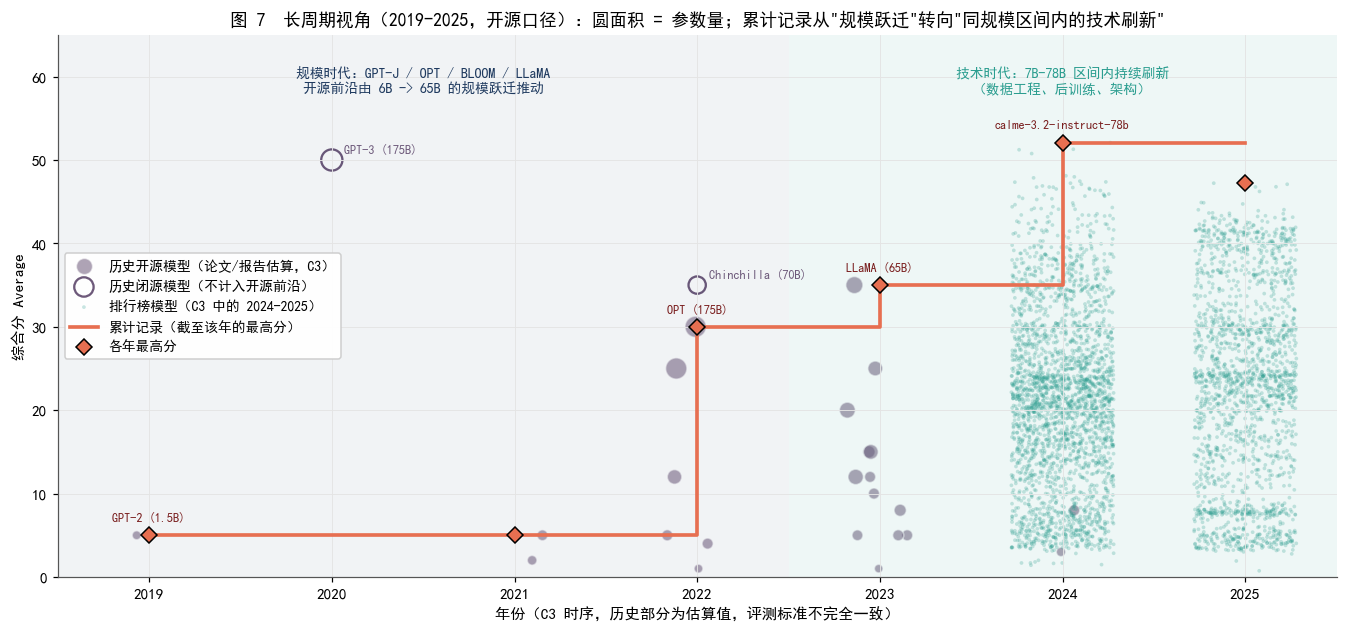

数据驱动 q90 算力增长变化点 = 2024.50 年（前段 n=311，后段 n=184）；固定 baseline = 2023.50
变化点前: n=311, q90 前沿算力年增 x3.01 [2.41, 3.58]
变化点后: n=184, q90 前沿算力年增 x1.47 [0.58, 2.26]
算力增长情景 G_phys: {'延续（数据驱动最近段）': 1.47, '放缓（对数增长率减半）': 1.21, '停滞（前沿算力不增长）': 1.0} ；固定 2023.5 baseline 年增 x2.67
数据截止 2025-03-13 前开源 LM 最大训练算力 3.80e+25；桥接锚点算力 7.80e+24；截止后 C4 新开源 LM 94 个（只作事后核对）


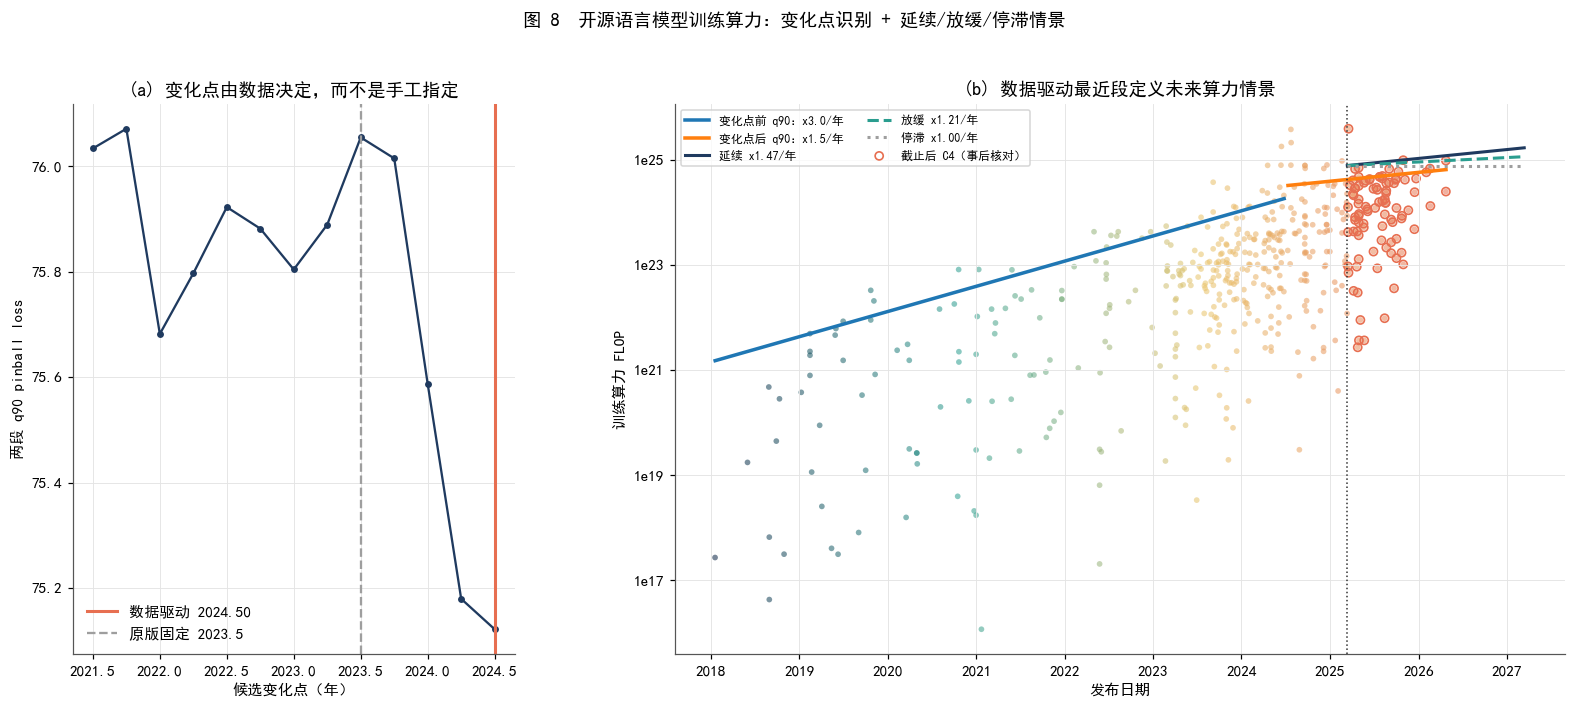

In [36]:
# ============ 4. 长周期视角 + 算力增长情景 ============
C3['is_hist'] = C3['Source'].str.startswith('Historical'); C3['S3'] = C3['Average']
CLOSED_HIST = ('GPT-3', 'Chinchilla')                                   # 历史模型中未开源权重者（不计入开源前沿）
C3['is_open'] = ~(C3['is_hist'] & C3['Model'].str.startswith(CLOSED_HIST))
C3o = C3[C3['is_open']]; yr_max = C3o.groupby('Year').apply(lambda d: d.loc[d['S3'].idxmax()])[['Model', 'Params_B', 'S3']]; yr_front = yr_max.copy(); yr_front['S3'] = yr_max['S3'].cummax()
for y_ in yr_front.index:                                   # 累计记录的保持者
    hold = yr_max[yr_max['S3'] == yr_front.loc[y_, 'S3']].index.min(); yr_front.loc[y_, ['Model', 'Params_B']] = yr_max.loc[hold, ['Model', 'Params_B']]
print('C3 各年最高分与累计记录（仅开源权重模型；GPT-3 与 Chinchilla 为闭源，剔除）:'); display(yr_max.join(yr_front[['S3']].rename(columns={'S3': '累计记录'})))
fig, ax = plt.subplots(figsize=(15, 6.4))
h = C3[C3.is_hist & C3.is_open]; ax.scatter(h['Year'] + RNG.uniform(-0.18, 0.18, len(h)), h['S3'], s=18 + 2.2 * np.sqrt(h['Params_B']) * 6, color=C_PLUM, alpha=0.55, edgecolor='white', label='历史开源模型（论文/报告估算，C3）')
hc = C3[C3.is_hist & ~C3.is_open]; ax.scatter(hc['Year'], hc['S3'], s=18 + 2.2 * np.sqrt(hc['Params_B']) * 6, facecolors='none', edgecolors=C_PLUM, linewidths=1.5, label='历史闭源模型（不计入开源前沿）')
for _, r in hc.iterrows(): ax.annotate(r['Model'], (r['Year'], r['S3']), xytext=(8, 4), textcoords='offset points', fontsize=8, color=C_PLUM)
lb3 = C3[~C3.is_hist]; ax.scatter(lb3['Year'] + RNG.uniform(-0.28, 0.28, len(lb3)), lb3['S3'], s=6, color=C_TEAL, alpha=0.25, edgecolor='none', label='排行榜模型（C3 中的 2024-2025）')
ax.step(yr_front.index, yr_front['S3'], where='post', color=C_CORAL, lw=2.4, label='累计记录（截至该年的最高分）'); ax.plot(yr_max.index, yr_max['S3'], color=C_CORAL, lw=0, marker='D', ms=7, mec='black', label='各年最高分')
last = None
for y_, r in yr_front.iterrows():
    if r['Model'] != last: ax.annotate('%s' % r['Model'].split('/')[-1][:24], (y_, r['S3']), xytext=(0, 9), textcoords='offset points', ha='center', fontsize=8, color=C_RUST); last = r['Model']
ax.axvspan(2018.5, 2022.5, color=C_NAVY, alpha=0.06, lw=0); ax.axvspan(2022.5, 2025.5, color=C_TEAL, alpha=0.08, lw=0)
ax.text(2020.5, 58, '规模时代：GPT-J / OPT / BLOOM / LLaMA\n开源前沿由 6B -> 65B 的规模跃迁推动', ha='center', fontsize=9, color=C_NAVY); ax.text(2024, 58, '技术时代：7B-78B 区间内持续刷新\n（数据工程、后训练、架构）', ha='center', fontsize=9, color=C_TEAL)
ax.set_xlim(2018.5, 2025.5); ax.set_ylim(0, 65); ax.set_xlabel('年份（C3 时序，历史部分为估算值，评测标准不完全一致）'); ax.set_ylabel('综合分 Average'); ax.legend(frameon=True, fontsize=9, loc='center left', facecolor='white', framealpha=0.95)
ax.set_title('图 7  长周期视角（2019-2025，开源口径）：圆面积 = 参数量；累计记录从"规模跃迁"转向"同规模区间内的技术刷新"', fontsize=11.5)
savefig('fig07_long_horizon_eras.png'); plt.show()

# C4：开源语言模型的前沿训练算力 + 数据驱动变化点
OW = C4L.dropna(subset=['C', 'date_pub4']); OW = OW[(OW['open_w'] == 'Yes') & (OW['date_pub4'] >= '2018-01-01')].copy(); OW['yr'] = OW['date_pub4'].dt.year + OW['date_pub4'].dt.dayofyear / 365.25; OW['log10C'] = np.log10(OW['C'])
def pinball(resid, q=.9): return np.where(resid >= 0, q * resid, (q - 1) * resid).sum()
def fit_qtrend(d, q=.9):
    X = np.column_stack([np.ones(len(d)), d['yr'] - 2020]); b = quantreg(X, d['log10C'].values, q); return b, pinball(d['log10C'].values - X @ b, q)
# 搜索变化点；每段至少 25 个样本
candidates = np.arange(2021.5, min(2024.6, OW['yr'].max() - .35), .25); cp_rows=[]
for cp in candidates:
    d1, d2 = OW[OW.yr < cp], OW[OW.yr >= cp]
    if min(len(d1), len(d2)) < 25: continue
    b1, l1 = fit_qtrend(d1); b2, l2 = fit_qtrend(d2); cp_rows.append({'cut': cp, 'loss': l1 + l2, 'n1': len(d1), 'n2': len(d2), 'b1': b1, 'b2': b2})
CP = pd.DataFrame(cp_rows); cp_best = CP.loc[CP['loss'].idxmin()]; CP_YEAR = float(cp_best['cut'])
print('数据驱动 q90 算力增长变化点 = %.2f 年（前段 n=%d，后段 n=%d）；固定 baseline = 2023.50' % (CP_YEAR, cp_best['n1'], cp_best['n2']))
seg = {'变化点前': OW[OW.yr < CP_YEAR], '变化点后': OW[OW.yr >= CP_YEAR]}; GR = {}
for name, d in seg.items():
    X = np.column_stack([np.ones(len(d)), d['yr'] - 2020]); b9 = quantreg(X, d['log10C'].values, 0.9); bmed = quantreg(X, d['log10C'].values, 0.5)
    bo = np.array([quantreg(X[ii], d['log10C'].values[ii], 0.9)[1] for ii in (RNG.integers(0, len(d), len(d)) for _ in range(N_BOOT))])
    GR[name] = {'n': len(d), 'slope_q90': b9[1], 'mult_q90': 10 ** b9[1], 'ci_mult': (10 ** np.percentile(bo, [2.5, 97.5])).tolist(), 'slope_q50': bmed[1], 'b9': b9}
    print('%s: n=%d, q90 前沿算力年增 x%.2f [%.2f, %.2f]' % (name, len(d), GR[name]['mult_q90'], *GR[name]['ci_mult']))
# 固定 2023.5 baseline
D_FIX = OW[OW.yr >= 2023.5]; b_fix, _ = fit_qtrend(D_FIX); G_FIX = 10 ** b_fix[1]
G_RECENT = GR['变化点后']['mult_q90']; SCEN = {'延续（数据驱动最近段）': G_RECENT, '放缓（对数增长率减半）': float(np.sqrt(G_RECENT)), '停滞（前沿算力不增长）': 1.0}
print('算力增长情景 G_phys:', {k: round(v, 2) for k, v in SCEN.items()}, '；固定 2023.5 baseline 年增 x%.2f' % G_FIX)
last_date = LB['date_sub'].max(); anchor = OW[OW['date_pub4'] <= last_date].sort_values('C', ascending=False).head(5)
C_ANCHOR_MAX = float(anchor['C'].iloc[0]); q_row = C4L[C4L['key'] == norm_name('Qwen/Qwen2.5-72B')]; C_ANCHOR_LB = float(q_row['C'].iloc[0]) if len(q_row) else float(anchor['C'].median())
after = OW[OW['date_pub4'] > last_date]
print('数据截止 %s 前开源 LM 最大训练算力 %.2e；桥接锚点算力 %.2e；截止后 C4 新开源 LM %d 个（只作事后核对）' % (last_date.date(), C_ANCHOR_MAX, C_ANCHOR_LB, len(after)))
pd.DataFrame([{'段': k, **{kk: vv for kk, vv in v.items() if kk != 'b9'}} for k, v in GR.items()]).to_csv(TAB / 'compute_growth_fits.csv', index=False, encoding='utf-8-sig'); CP[['cut','loss','n1','n2']].to_csv(TAB / 'compute_changepoint_search.csv', index=False, encoding='utf-8-sig')

# ---- 图 8：变化点证据 + 开源 LM 前沿算力与情景锥 ----
fig = plt.figure(figsize=(17.5, 6.5)); gs = gridspec.GridSpec(1, 2, width_ratios=[.72, 1.45], wspace=.24)
ax=fig.add_subplot(gs[0]); ax.plot(CP['cut'], CP['loss'], marker='o', ms=3.5, lw=1.5, color=C_NAVY); ax.axvline(CP_YEAR, color=C_CORAL, lw=2, label='数据驱动 %.2f' % CP_YEAR); ax.axvline(2023.5, color=C_GREY, lw=1.5, ls='--', label='原版固定 2023.5'); ax.set_xlabel('候选变化点（年）'); ax.set_ylabel('两段 q90 pinball loss'); ax.set_title('(a) 变化点由数据决定，而不是手工指定'); ax.legend(frameon=False)
ax=fig.add_subplot(gs[1]); sc=ax.scatter(OW['date_pub4'], OW['C'], s=14, c=OW['yr'], cmap=CMAP_TIME, alpha=.55, edgecolor='none')
for name,v in GR.items():
    d=seg[name]; xs=np.linspace(d.yr.min(), d.yr.max(),60); ys=10**(v['b9'][0]+v['b9'][1]*(xs-2020)); ax.plot([pd.Timestamp('2020-01-01')+pd.Timedelta(days=365.25*(x-2020)) for x in xs], ys, lw=2.3, label='%s q90：x%.1f/年' % (name,v['mult_q90']))
hs=np.linspace(0,24,25); SC_COL={list(SCEN)[0]:C_NAVY,list(SCEN)[1]:C_TEAL,list(SCEN)[2]:C_GREY}
for name,G in SCEN.items(): ax.plot([last_date+pd.Timedelta(days=30.4375*h) for h in hs], C_ANCHOR_LB*G**(hs/12), color=SC_COL[name], lw=2.0, ls='--' if '放缓' in name else ':' if '停滞' in name else '-', label='%s x%.2f/年' % (name.split('（')[0],G))
if len(after): ax.scatter(after['date_pub4'], after['C'], s=28, facecolors='none', edgecolors=C_CORAL, linewidths=1.1, label='截止后 C4（事后核对）')
ax.axvline(last_date,color='#333333',lw=1,ls=':'); ax.set_yscale('log'); ax.yaxis.set_major_formatter(pow10); ax.set_xlabel('发布日期'); ax.set_ylabel('训练算力 FLOP'); ax.legend(frameon=True,fontsize=7.8,ncol=2,loc='upper left'); ax.set_title('(b) 数据驱动最近段定义未来算力情景')
fig.suptitle('图 8  开源语言模型训练算力：变化点识别 + 延续/放缓/停滞情景', fontsize=12, y=1.01); savefig('fig08_compute_changepoint_scenarios.png'); plt.show()


## 5. Loss–Benchmark 桥接：保留 logistic 结构，升级权重为“可比性先验 × 残差方差”

问题三输出的是最优交叉熵损失 $L^\star(C)$，而问题四预测的是 Benchmark 综合分 $S$。原版 logistic 桥接
$$S=100\sigma[a+b(L_0-L)+cI(chat)]$$
符合“损失下降、分数上升且趋于饱和”的形状约束，因此 **结构不换**。

原版把高/中可比样本固定权重设为 1 / 0.5；创新版做 3 轮 IRLS 异方差更新：先用原权重拟合，再按各 tier 的残差方差反向加权，同时保留可比性先验。固定权重与自适应权重通过 5-fold CV 比较，若自适应没有改善，则自动使用原桥接。

这里仍强调：桥接只负责把前三问的 Loss 链条翻译为问题四的分数尺度，是 **交叉核对通道**，不是未来前沿的唯一预测主链。


桥接选择：fixed-CV RMSE 8.42，adaptive-CV RMSE 8.49 -> 使用自适应权重
最终桥接 S=100 sigma(-2.609 + 1.726(2.5-L) + 0.880 chat)，R2=0.479；tier residual std={'中可比': 8.62, '高可比': 2.35}
高可比子集 n=7，最终桥接 RMSE=4.82

问题三最终接口 -> 问题四 Loss-Benchmark 桥接
Q3 主成本 = 指数型；预算范围 [1.0e+19, 1.0e+24]
高算力外推: L*(C) = 1.6898 + 2007 * C^(-0.1674)

问题三最优损失 -> 综合分（桥接）:
  C = 1.0e+22: L* = 2.094 -> S(pretrained) = 12.9, S(chat) = 26.3
  C = 7.8e+24: L* = 1.826 -> S(pretrained) = 19.1, S(chat) = 36.2
  C = 1.0e+25: L* = 1.821 -> S(pretrained) = 19.2, S(chat) = 36.4
  C = 1.0e+26: L* = 1.779 -> S(pretrained) = 20.4, S(chat) = 38.1


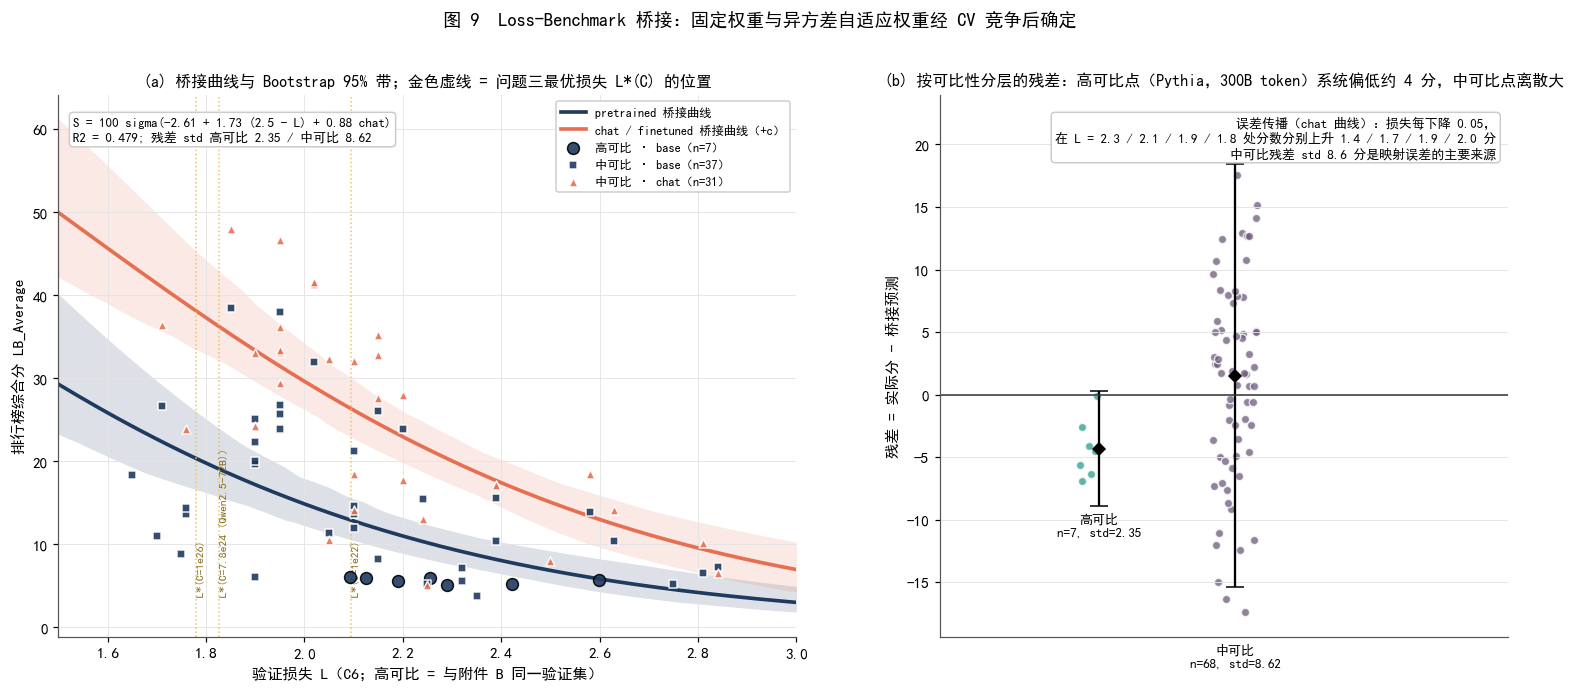

In [38]:
# ============ 5. Loss-Benchmark 桥接：固定权重 vs 异方差自适应权重 ============
B = C6.copy(); B['chat'] = B['Model'].str.lower().str.contains('instruct|-it$|chat|-it-|orpo|dpo').astype(float)
B['tier'] = np.where(B['Loss_Comparability'].str.startswith('High'), '高可比', '中可比'); B['w_base'] = np.where(B['tier'] == '高可比', 1.0, 0.5)
L0 = 2.5
def bridge(th, L, chat): return 100 * expit(th[0] + th[1] * (L0 - np.asarray(L, float)) + th[2] * np.asarray(chat, float))
def fit_bridge(d, w): return least_squares(lambda th: np.sqrt(np.asarray(w)) * (bridge(th, d['Val_Loss'], d['chat']) - d['LB_Average']), [-2.0, 3.0, 0.5]).x
TH_FIXED = fit_bridge(B, B['w_base'].values)
# IRLS：可比性先验 x inverse residual variance，方差做 pooled shrinkage 防止高可比仅 7 点过拟合
w = B['w_base'].values.copy(); pooled_prior = 5.0
for _ in range(3):
    th = fit_bridge(B, w); rr = B['LB_Average'].values - bridge(th, B['Val_Loss'], B['chat']); pv = np.mean(rr**2); inv=[]
    for tier, r in zip(B['tier'], rr):
        mask=(B['tier']==tier).values; v=(np.sum(rr[mask]**2)+pooled_prior*pv)/(mask.sum()+pooled_prior); inv.append(1/max(v,1e-6))
    inv=np.asarray(inv); w=B['w_base'].values*inv; w=w/w.max()
TH_ADAPT = fit_bridge(B, w)

def bridge_cv(theta_mode='fixed', K=5):
    errs=[]; order=np.arange(len(B))
    for k in range(K):
        te=(order%K)==k; tr=~te; dtr=B.iloc[tr]
        if theta_mode=='fixed': th=fit_bridge(dtr,dtr['w_base'].values)
        else:
            ww=dtr['w_base'].values.copy()
            for _ in range(3):
                th=fit_bridge(dtr,ww); rr=dtr['LB_Average'].values-bridge(th,dtr['Val_Loss'],dtr['chat']); pv=np.mean(rr**2); inv=[]
                for tier in dtr['tier']:
                    mask=(dtr['tier']==tier).values; v=(np.sum(rr[mask]**2)+pooled_prior*pv)/(mask.sum()+pooled_prior); inv.append(1/max(v,1e-6))
                ww=dtr['w_base'].values*np.asarray(inv); ww=ww/ww.max()
            th=fit_bridge(dtr,ww)
        pred=bridge(th,B.iloc[te]['Val_Loss'],B.iloc[te]['chat']); errs.extend((B.iloc[te]['LB_Average'].values-pred).tolist())
    return float(np.sqrt(np.mean(np.square(errs))))
rm_fixed, rm_adapt = bridge_cv('fixed'), bridge_cv('adapt')
USE_ADAPT = rm_adapt <= 1.02*rm_fixed; TH_B = TH_ADAPT if USE_ADAPT else TH_FIXED; B['w'] = w if USE_ADAPT else B['w_base']
B['pred'] = bridge(TH_B, B['Val_Loss'], B['chat']); B['res'] = B['LB_Average'] - B['pred']; SIG = B.groupby('tier')['res'].std().to_dict(); R2b = 1 - (B['res']**2).sum()/((B['LB_Average']-B['LB_Average'].mean())**2).sum()
print('桥接选择：fixed-CV RMSE %.2f，adaptive-CV RMSE %.2f -> %s' % (rm_fixed, rm_adapt, '使用自适应权重' if USE_ADAPT else '回退原固定权重'))
print('最终桥接 S=100 sigma(%.3f + %.3f(2.5-L) + %.3f chat)，R2=%.3f；tier residual std=%s' % (TH_B[0],TH_B[1],TH_B[2],R2b,{k:round(v,2) for k,v in SIG.items()}))
BOOT_B=np.array([fit_bridge(B.iloc[ii],B['w'].values[ii]) for ii in (RNG.integers(0,len(B),len(B)) for _ in range(N_BOOT))])
hi=B[B['tier']=='高可比']; print('高可比子集 n=%d，最终桥接 RMSE=%.2f' % (len(hi),np.sqrt((hi['res']**2).mean())))
B.to_csv(TAB/'bridge_fit.csv',index=False,encoding='utf-8-sig'); json.dump({'theta':TH_B.tolist(),'L0':L0,'sigma_tier':SIG,'R2':float(R2b),'cv_rmse_fixed':rm_fixed,'cv_rmse_adapt':rm_adapt,'use_adapt':bool(USE_ADAPT),'boot':BOOT_B.tolist()},open(TAB/'bridge_params.json','w',encoding='utf-8'),ensure_ascii=False)

# ============ 问题三最终接口：L*(C) -> S*(C) ============
# Q3 最终版不再提供 loss_budget_curve_default，
# 而是提供 optimal_configs_default_Lctx。
#
# 主口径采用问题三中的“指数型成本”；
# 幂函数型、对数渐进型留作敏感性分析。
#
# 对 Q3 已计算区间采用 log-C 插值；
# 超出 1e24 后不能使用 np.interp 的常数外推，
# 因此用问题二/三的不可约损失 E 约束幂律：
#
#       L*(C) = E + K C^{-eta}
#
# 对 Q3 三个预算点拟合 K, eta。

Q3_OPT = Q3['optimal_configs_default_Lctx']

COST_MAIN = '指数型'
COST_SENS = ['指数型', '幂函数型', '对数渐进型']

def extract_q3_curve(cost_name):
    rows = []

    for c_key, block in Q3_OPT.items():
        C = float(c_key)

        if cost_name not in block:
            continue

        cfg = block[cost_name]['executable']

        rows.append({
            'C': C,
            'loss': float(cfg['loss']),
            'N': float(cfg['N']),
            'D': float(cfg['D']),
            'Q': float(cfg['Q'])
        })

    df = pd.DataFrame(rows).sort_values('C').reset_index(drop=True)

    if len(df) < 2:
        raise RuntimeError(
            f'问题三接口中成本函数 {cost_name} 的有效预算点不足'
        )

    return df


Q3_CURVES = {
    c: extract_q3_curve(c)
    for c in COST_SENS
    if all(c in v for v in Q3_OPT.values())
}

Q3_MAIN = Q3_CURVES[COST_MAIN]

C_curve = Q3_MAIN['C'].values.astype(float)
L_curve = Q3_MAIN['loss'].values.astype(float)

# 问题二/三经典 scaling law 的不可约损失
E_q3 = float(Q3['inputs']['classic_law']['E'])

# ---------- 受不可约损失约束的高算力外推 ----------
# log(L-E) = log K - eta log C
gap = L_curve - E_q3

if np.any(gap <= 0):
    raise RuntimeError(
        'Q3 最优 Loss 已低于/等于不可约损失 E，无法进行受约束幂律外推'
    )

x_fit = np.log(C_curve)
y_fit = np.log(gap)

coef = np.polyfit(x_fit, y_fit, 1)

eta_q3 = float(max(-coef[0], 1e-6))
K_q3 = float(np.exp(coef[1]))

C_MIN_Q3 = float(C_curve.min())
C_MAX_Q3 = float(C_curve.max())


def L_star(C, cost_name=COST_MAIN):
    """
    问题三可执行最优 Loss 的连续接口。

    - Q3 已覆盖区间：log(C) 线性插值；
    - 高于最大预算：E + K*C^{-eta} 约束外推；
    - 低于最小预算：保持最左端，仅防止无依据反向外推。
    """
    C = np.asarray(C, dtype=float)
    scalar = (C.ndim == 0)

    C1 = np.atleast_1d(C)

    if cost_name == COST_MAIN:
        df = Q3_MAIN
        E = E_q3
        K = K_q3
        eta = eta_q3
    else:
        df = Q3_CURVES[cost_name]

        cc = df['C'].values.astype(float)
        ll = df['loss'].values.astype(float)

        gg = ll - E_q3

        if np.all(gg > 0):
            cf = np.polyfit(np.log(cc), np.log(gg), 1)
            eta = float(max(-cf[0], 1e-6))
            K = float(np.exp(cf[1]))
        else:
            eta = eta_q3
            K = K_q3

        E = E_q3

    cc = df['C'].values.astype(float)
    ll = df['loss'].values.astype(float)

    out = np.empty_like(C1, dtype=float)

    inside = (C1 >= cc.min()) & (C1 <= cc.max())
    high = C1 > cc.max()
    low = C1 < cc.min()

    # 观测/求解范围内：log-compute 插值
    if inside.any():
        out[inside] = np.interp(
            np.log10(C1[inside]),
            np.log10(cc),
            ll
        )

    # 高算力：受 E 约束的 scaling 外推
    if high.any():
        out[high] = E + K * C1[high] ** (-eta)

    # 不向低算力区间进行无依据外推
    if low.any():
        out[low] = ll[0]

    return float(out[0]) if scalar else out


def S_star(C, chat, th=None):
    th = TH_B if th is None else th
    return bridge(th, L_star(C), chat)


print('\n问题三最终接口 -> 问题四 Loss-Benchmark 桥接')
print(
    'Q3 主成本 = %s；预算范围 [%.1e, %.1e]' %
    (COST_MAIN, C_MIN_Q3, C_MAX_Q3)
)
print(
    '高算力外推: L*(C) = %.4f + %.4g * C^(-%.4f)'
    % (E_q3, K_q3, eta_q3)
)

print('\n问题三最优损失 -> 综合分（桥接）:')
for C in (1e22, 7.8e24, 1e25, 1e26):
    print(
        '  C = %.1e: L* = %.3f -> '
        'S(pretrained) = %.1f, S(chat) = %.1f'
        % (
            C,
            L_star(C),
            S_star(C, 0),
            S_star(C, 1)
        )
    )

# ---- 图 9：桥接曲线（分层）+ 残差与误差传播 ----
fig = plt.figure(figsize=(17, 6.4)); gs = gridspec.GridSpec(1, 2, width_ratios=[1.3, 1], wspace=0.22)
ax = fig.add_subplot(gs[0]); Lg = np.linspace(1.5, 3.0, 200)
for chat_, c, lab in ((0, C_NAVY, 'pretrained 桥接曲线'), (1, C_CORAL, 'chat / finetuned 桥接曲线（+c）')):
    band = np.array([bridge(th, Lg, chat_) for th in BOOT_B]); ax.fill_between(Lg, np.percentile(band, 2.5, axis=0), np.percentile(band, 97.5, axis=0), color=c, alpha=0.15, lw=0)
    ax.plot(Lg, bridge(TH_B, Lg, chat_), color=c, lw=2.4, label=lab)
for (tier, chat_), mk in (( '高可比', 0), 'o'), (('中可比', 0), 's'), (('中可比', 1), '^'):
    d = B[(B['tier'] == tier) & (B['chat'] == chat_)]
    if len(d): ax.scatter(d['Val_Loss'], d['LB_Average'], marker=mk, s=60 if tier == '高可比' else 34, color=C_NAVY if chat_ == 0 else C_CORAL, edgecolor='black' if tier == '高可比' else 'white', linewidths=1, alpha=0.9, zorder=4, label='%s · %s（n=%d）' % (tier, 'chat' if chat_ else 'base', len(d)))
for C, lab in ((1e22, '1e22'), (7.8e24, '7.8e24 (Qwen2.5-72B)'), (1e26, '1e26')):
    ax.axvline(L_star(C), color=C_GOLD, lw=1, ls=':'); ax.text(L_star(C), 3, ' L*(C=%s)' % lab, rotation=90, fontsize=7.5, va='bottom', color='#8A6D1A')
ax.set_xlabel('验证损失 L（C6；高可比 = 与附件 B 同一验证集）'); ax.set_ylabel('排行榜综合分 LB_Average'); ax.set_xlim(1.5, 3.0); ax.legend(frameon=True, fontsize=8, loc='upper right', facecolor='white', framealpha=0.95)
ax.text(0.02, 0.96, 'S = 100 sigma(%.2f + %.2f (2.5 - L) + %.2f chat)\nR2 = %.3f; 残差 std 高可比 %.2f / 中可比 %.2f' % (TH_B[0], TH_B[1], TH_B[2], R2b, SIG.get('高可比', np.nan), SIG.get('中可比', np.nan)), transform=ax.transAxes, va='top', fontsize=8.5, bbox=dict(boxstyle='round', fc='white', ec='#CCCCCC'))
ax.set_title('(a) 桥接曲线与 Bootstrap 95% 带；金色虚线 = 问题三最优损失 L*(C) 的位置', fontsize=10.5)
ax = fig.add_subplot(gs[1])
for tier, c, off in (('高可比', C_TEAL, -0.18), ('中可比', C_PLUM, 0.18)):
    d = B[B['tier'] == tier]; ax.scatter(np.full(len(d), off) + RNG.uniform(-0.06, 0.06, len(d)), d['res'], s=30, color=c, alpha=0.75, edgecolor='white')
    ax.errorbar([off], [d['res'].mean()], yerr=[[1.96 * d['res'].std()]], fmt='D', color='black', capsize=6, ms=6)
    ax.text(off, d['res'].min() - 2.5, '%s\nn=%d, std=%.2f' % (tier, len(d), d['res'].std()), ha='center', va='top', fontsize=8.5)
ax.axhline(0, color='#333333', lw=1); ax.set_xlim(-0.6, 0.9); ax.set_xticks([]); ax.set_ylabel('残差 = 实际分 - 桥接预测')
# 误差传播示意：损失的一个小扰动 dL 对应的分数不确定性
Ls = np.array([2.3, 2.1, 1.9, 1.8]); dS = 100 * TH_B[1] * expit(TH_B[0] + TH_B[1] * (L0 - Ls) + TH_B[2]) * (1 - expit(TH_B[0] + TH_B[1] * (L0 - Ls) + TH_B[2])) * 0.05
ax.text(0.98, 0.96, '误差传播（chat 曲线）：损失每下降 0.05，\n在 L = 2.3 / 2.1 / 1.9 / 1.8 处分数分别上升 %s 分\n中可比残差 std %.1f 分是映射误差的主要来源' % (' / '.join('%.1f' % float(v) for v in dS), float(SIG.get('中可比', np.nan))), transform=ax.transAxes, ha='right', va='top', fontsize=8.5, bbox=dict(boxstyle='round', fc='white', ec='#CCCCCC'))
ax.set_title('(b) 按可比性分层的残差：高可比点（Pythia，300B token）系统偏低约 %.0f 分，中可比点离散大' % abs(B.loc[B['tier'] == '高可比', 'res'].mean()), fontsize=10.5)
fig.suptitle('图 9  Loss-Benchmark 桥接：固定权重与异方差自适应权重经 CV 竞争后确定', fontsize=12, y=1.0)
savefig('fig09_loss_benchmark_bridge.png'); plt.show()


## 6. 未来 12 / 24 个月前沿：暴露校正 + 多折时序回测 + 安全回退

### 6.1 五个候选预测器

**A0 原版记录对数律**：
$$\operatorname{logit}(F/100)=a+b\ln(1+\tau).$$

**A1 EARF 暴露校正记录前沿**：
$$\operatorname{logit}(F/100)=a+b\ln(1+M(\tau))+c\tau,$$
未来累计暴露量用最近 6 个月月度提交量的中位数外推。$b$ 表示“候选池扩大”的极值效应，$c$ 表示控制暴露后的前沿漂移。

**B0 原版算力 OLS**、**B1 算力 q90**、**B2 DATF q90**：统一从当前前沿出发，把未来增量写为
$$\Delta y=\beta_C\frac{h}{12}\ln G_{phys}+\gamma_{tech}h,$$
其中 $G_{phys}$ 分为延续、对数增长率减半、停滞三档。DATF 使用拆除了提交延迟后的 $\gamma_{tech}$。

### 6.2 rolling-origin 回测与 baseline safeguard
用若干历史月末作为预测原点，只使用该日期之前的数据拟合，向后预测 3 个月；所有候选在完全相同的 folds 上比较 MAE。模型权重
$$w_m\propto\exp[-\lambda E_m/\operatorname{median}(E)],$$
并设置安全阀：若融合后的滚动 MAE 高于最好的 **原版 baseline（A0/B0）**，最终权重退化为该 baseline 的 one-hot 权重。这样创新模型只有在历史样本外证据支持时才进入最终预测。

### 6.3 不确定性
参数不确定性仍用模型级 Bootstrap；滚动回测的绝对残差再给出 conformal-inspired 校准量 $q_{1-\alpha}$，将 5%–95% Bootstrap 区间扩张为经验校准区间。考虑到该序列存在分布漂移，这里不宣称严格 i.i.d. conformal 保证，而报告“滚动残差校准后的经验区间”。


rolling-origin 回测:


,类型,模型,MAE,RMSE,folds
0,chat/finetuned,A0_time,4.4696,4.6510,4
1,chat/finetuned,A1_exposure,12.1859,24.3718,4
2,chat/finetuned,B0_OLS,3.2145,3.2278,4
3,chat/finetuned,B1_Q90,3.1625,3.1677,4
4,chat/finetuned,B2_DATF,5.3325,5.8933,4
5,pretrained,A0_time,4.7149,5.1600,4
6,pretrained,A1_exposure,14.4866,16.8495,4
7,pretrained,B0_OLS,3.9888,4.1975,4
8,pretrained,B1_Q90,3.9317,4.1931,4
9,pretrained,B2_DATF,6.0048,6.7008,4


pretrained: final=fallback_to_B0_OLS, CV MAE 3.989 vs best baseline B0_OLS 3.989, weights={'A0_time': 0.0, 'A1_exposure': 0.0, 'B0_OLS': 1.0, 'B1_Q90': 0.0, 'B2_DATF': 0.0}
chat/finetuned: final=fallback_to_B0_OLS, CV MAE 3.214 vs best baseline B0_OLS 3.214, weights={'A0_time': 0.0, 'A1_exposure': 0.0, 'B0_OLS': 1.0, 'B1_Q90': 0.0, 'B2_DATF': 0.0}

未来前沿预测:


,路线,类型,情景,月数,中位数,Bootstrap 5%,Bootstrap 95%,校准5%,校准95%,校准扩张q,safeguard
0,ROAE 综合,pretrained,延续（数据驱动最近段）,12,46.8200,42.1700,50.9100,38.0100,57.1600,6.2400,fallback_to_B0_OLS
1,ROAE 综合,pretrained,延续（数据驱动最近段）,24,55.6600,45.9800,63.7800,39.7300,70.0300,6.2400,fallback_to_B0_OLS
2,ROAE 综合,pretrained,放缓（对数增长率减半）,12,45.8700,41.6300,49.7000,38.0100,55.9400,6.2400,fallback_to_B0_OLS
3,ROAE 综合,pretrained,放缓（对数增长率减半）,24,53.9300,45.0700,60.7500,38.8200,67.0000,6.2400,fallback_to_B0_OLS
4,ROAE 综合,pretrained,停滞（前沿算力不增长）,12,45.2700,40.7700,49.2500,38.0100,55.5000,6.2400,fallback_to_B0_OLS
5,ROAE 综合,pretrained,停滞（前沿算力不增长）,24,52.7300,43.1000,59.2100,38.0100,65.4500,6.2400,fallback_to_B0_OLS
6,ROAE 综合,chat/finetuned,延续（数据驱动最近段）,12,60.0700,55.2200,64.0800,51.6700,67.6300,3.5400,fallback_to_B0_OLS
7,ROAE 综合,chat/finetuned,延续（数据驱动最近段）,24,68.3900,59.5100,74.9900,55.9600,78.5300,3.5400,fallback_to_B0_OLS
8,ROAE 综合,chat/finetuned,放缓（对数增长率减半）,12,59.2700,54.8500,62.8100,51.3000,66.3500,3.5400,fallback_to_B0_OLS
9,ROAE 综合,chat/finetuned,放缓（对数增长率减半）,24,66.8800,58.5000,72.7700,54.9500,76.3200,3.5400,fallback_to_B0_OLS



Loss 链条交叉核对（差值不再直接命名为“后训练因果贡献”）:


,类型,情景,月数,当前前沿,Loss链条前沿(中位),Loss链条增量,ROAE总增量,桥接未解释增益,dL中位
0,pretrained,延续（数据驱动最近段）,12,38.0100,39.5400,1.5400,8.8100,7.2800,0.0400
1,pretrained,延续（数据驱动最近段）,24,38.0100,40.7000,2.6900,17.6500,14.9700,0.0700
2,pretrained,放缓（对数增长率减半）,12,38.0100,39.4200,1.4100,7.8600,6.4500,0.0300
3,pretrained,放缓（对数增长率减半）,24,38.0100,40.4800,2.4700,15.9200,13.4500,0.0600
4,pretrained,停滞（前沿算力不增长）,12,38.0100,39.2800,1.2700,7.2700,6.0000,0.0300
5,pretrained,停滞（前沿算力不增长）,24,38.0100,40.2600,2.2500,14.7200,12.4800,0.0600
6,chat/finetuned,延续（数据驱动最近段）,12,51.2300,52.8500,1.6200,8.8300,7.2200,0.0400
7,chat/finetuned,延续（数据驱动最近段）,24,51.2300,53.9700,2.7400,17.1600,14.4100,0.0700
8,chat/finetuned,放缓（对数增长率减半）,12,51.2300,52.7200,1.4900,8.0400,6.5500,0.0300
9,chat/finetuned,放缓（对数增长率减半）,24,51.2300,53.8200,2.5900,15.6500,13.0600,0.0600


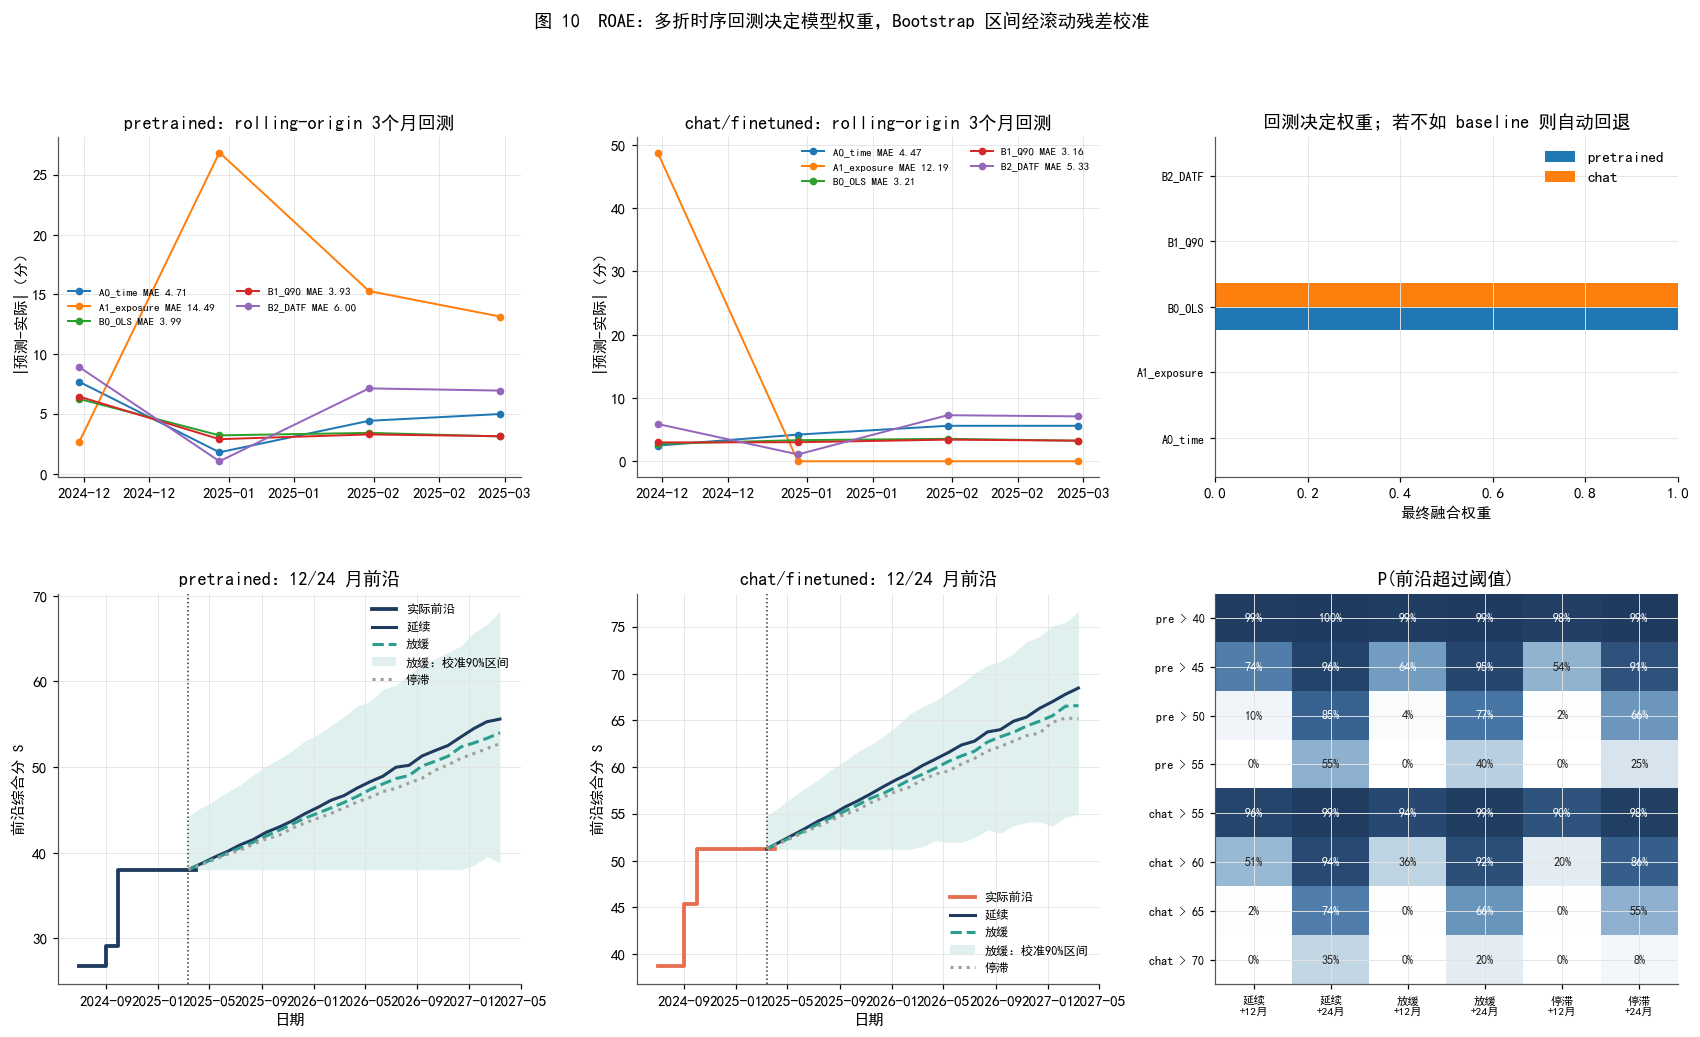

In [40]:
# ============ 6. 前沿预测：EARF + rolling-origin adaptive ensemble ============
H=[12,24]; tau_end=float(LB['tau'].max()); last_date=LB['date_sub'].max(); FC=[]

def monthly_frontier(df, end_date=None):
    d=df.copy()
    if end_date is not None: d=d[d['date_sub']<=pd.Timestamp(end_date)]
    d=d.sort_values('date_sub'); p=d['date_sub'].dt.to_period('M')
    grp=d.groupby(p).agg(month_max=('S','max'), n=('S','size')).sort_index(); grp['F']=grp['month_max'].cummax(); grp['M']=grp['n'].cumsum()
    grp['tau']=np.array([(x.to_timestamp(how='end')-T0).days/30.4375 for x in grp.index]); return grp

def fit_A0(grp):
    X=np.column_stack([np.ones(len(grp)),np.log1p(grp['tau'].values)]); return np.linalg.lstsq(X,logit(np.clip(grp['F'].values/100,1e-3,1-1e-3)),rcond=None)[0]
def pred_A0(b,t): return 100*expit(b[0]+b[1]*np.log1p(t))
def fit_A1(grp):
    X=np.column_stack([np.ones(len(grp)),np.log1p(grp['M'].values),grp['tau'].values]); return np.linalg.lstsq(X,logit(np.clip(grp['F'].values/100,1e-3,1-1e-3)),rcond=None)[0]
def recent_rate(grp,k=6): return float(max(1e-6,grp['n'].tail(min(k,len(grp))).median()))
def pred_A1(b,M_now,t_future,t_now,rate):
    M_future=M_now+rate*np.maximum(np.asarray(t_future)-t_now,0); return 100*expit(b[0]+b[1]*np.log1p(M_future)+b[2]*np.asarray(t_future))

def estimate_G_at(cut):
    d=OW[OW['date_pub4']<=pd.Timestamp(cut)].copy()
    if len(d)<30: return 1.0
    yr_cut=pd.Timestamp(cut).year+pd.Timestamp(cut).dayofyear/365.25; recent=d[d.yr>=yr_cut-2.5]
    if len(recent)<25: recent=d.tail(max(25,int(.45*len(d))))
    X=np.column_stack([np.ones(len(recent)),recent['yr']-2020]); b=quantreg(X,recent['log10C'].values,.9); return float(np.clip(10**b[1],.6,50))

def fit_B_candidates(mc):
    z=np.log(mc['C']); center=float(z.median()); zc=z-center; chat=(mc['type']=='chat/finetuned').astype(float).values; y=mc['y'].values
    X=np.column_stack([np.ones(len(mc)),zc,mc['tau_pub'],chat]); ols=np.linalg.lstsq(X,y,rcond=None)[0]; q=quantreg(X,y,.9)
    Xd=np.column_stack([np.ones(len(mc)),zc,mc['tau_pub'],mc['lag_month'],chat]); dual=quantreg(Xd,y,.9)
    return {'B0_OLS':ols,'B1_Q90':q,'B2_DATF':dual}

def point_B(F_now,h,G,b):
    beta,gamma=float(b[1]),float(b[2]); return float(max(F_now,100*expit(logit(F_now/100)+beta*(h/12)*np.log(G)+gamma*h))) if beta>0 else np.nan

# ---------- rolling-origin 多折时序回测 ----------
end_for_cut=last_date-pd.DateOffset(months=3); cuts=pd.date_range('2024-08-31',end_for_cut,freq='M')
BT=[]; CAND=['A0_time','A1_exposure','B0_OLS','B1_Q90','B2_DATF']
for g in ('pretrained','chat/finetuned'):
    dall=LB[(LB.type==g)&LB.open_strict].copy()
    for cut in cuts:
        train=dall[dall.date_sub<=cut]
        if len(train)<35: continue
        target=min(cut+pd.DateOffset(months=3),last_date); actual=float(dall[dall.date_sub<=target]['S'].max()); gr=monthly_frontier(train); F0=float(gr['F'].iloc[-1]); t0=float(gr['tau'].iloc[-1]); h=(target-cut).days/30.4375
        b0=fit_A0(gr); p0=max(F0,float(pred_A0(b0,t0+h)))
        b1=fit_A1(gr); p1=max(F0,float(pred_A1(b1,float(gr['M'].iloc[-1]),t0+h,t0,recent_rate(gr))))
        mc=MC[MC['date_sub']<=cut].copy(); G=estimate_G_at(cut); preds={'A0_time':p0,'A1_exposure':p1}
        if len(mc)>=30:
            bb=fit_B_candidates(mc); preds.update({k:point_B(F0,h,G,v) for k,v in bb.items()})
        for name in CAND:
            if name in preds and np.isfinite(preds[name]): BT.append({'类型':g,'cut':cut,'target':target,'h_month':h,'模型':name,'pred':preds[name],'actual':actual,'error':preds[name]-actual,'abs_error':abs(preds[name]-actual)})
BTDF=pd.DataFrame(BT); BTDF.to_csv(TAB/'rolling_origin_backtest.csv',index=False,encoding='utf-8-sig')
CV=BTDF.groupby(['类型','模型']).agg(MAE=('abs_error','mean'),RMSE=('error',lambda x:float(np.sqrt(np.mean(np.square(x))))),folds=('error','size')).reset_index(); print('rolling-origin 回测:'); display(CV)

# ---------- 由 CV 产生权重，并做 baseline safeguard ----------
WEIGHTS={}; SAFE={}
for g in ('pretrained','chat/finetuned'):
    d=CV[CV.类型==g].set_index('模型'); valid=[m for m in CAND if m in d.index]
    scale=max(float(d.loc[valid,'MAE'].median()),.2); raw=np.exp(-2.0*d.loc[valid,'MAE'].values/scale); w=raw/raw.sum(); wd={m:float(v) for m,v in zip(valid,w)}
    # 用相同 fold 上的加权点预测评估融合 MAE
    z=BTDF[BTDF.类型==g].pivot_table(index=['cut','target','actual'],columns='模型',values='pred').dropna(subset=valid,how='all').reset_index(); ens=[]
    for _,r in z.iterrows():
        av=[m for m in valid if np.isfinite(r.get(m,np.nan))]; ww=np.array([wd[m] for m in av]); ww=ww/ww.sum(); ens.append(np.dot(ww,[r[m] for m in av]))
    ens_mae=float(np.mean(np.abs(np.asarray(ens)-z['actual'].values))) if len(z) else np.inf
    bases=[m for m in ['A0_time','B0_OLS'] if m in d.index]; best_base=min(bases,key=lambda m:d.loc[m,'MAE']); base_mae=float(d.loc[best_base,'MAE'])
    if ens_mae>base_mae:
        wd={m:(1.0 if m==best_base else 0.0) for m in valid}; SAFE[g]='fallback_to_'+best_base; ens_mae=base_mae
    else: SAFE[g]='adaptive_ensemble'
    WEIGHTS[g]=wd; print('%s: final=%s, CV MAE %.3f vs best baseline %s %.3f, weights=%s' % (g,SAFE[g],ens_mae,best_base,base_mae,{k:round(v,3) for k,v in wd.items()}))

# ---------- 全数据拟合五个候选，并生成 Bootstrap 分布 ----------
def boot_A(df,kind,n=N_BOOT):
    out=[]
    for _ in range(n):
        ds=df.iloc[RNG.integers(0,len(df),len(df))]; gr=monthly_frontier(ds)
        if len(gr)<4: continue
        out.append(fit_A0(gr) if kind=='A0' else np.r_[fit_A1(gr),recent_rate(gr),gr['M'].iloc[-1],gr['tau'].iloc[-1]])
    return np.asarray(out)
A_RES={}
for g in ('pretrained','chat/finetuned'):
    d=LB[(LB.type==g)&LB.open_strict]; gr=monthly_frontier(d); F_now=float(gr.F.iloc[-1]);
    A_RES[g]={'grp':gr,'F_now':F_now,'A0':fit_A0(gr),'A1':fit_A1(gr),'bo0':boot_A(d,'A0'),'bo1':boot_A(d,'A1')}
# B bootstrap 候选来自第3节
BBOOT={'B0_OLS':bo_c_ols,'B1_Q90':bo_c_q,'B2_DATF':bo_dual}
G_phys_ci=GR['变化点后']['ci_mult']; sd_lnG=max(0.02,(np.log(G_phys_ci[1])-np.log(G_phys_ci[0]))/(2*1.96))
def draw_G(sname,n):
    G=SCEN[sname]
    if '停滞' in sname: return np.ones(n)
    return np.exp(RNG.normal(np.log(G),sd_lnG*(.5 if '放缓' in sname else 1.0),n))
def dist_candidate(g,name,h,sname,n=2500):
    ar=A_RES[g]; F0=ar['F_now']; t0=float(ar['grp'].tau.iloc[-1])
    if name=='A0_time':
        bo=ar['bo0']; ii=RNG.integers(0,len(bo),n); return np.maximum(F0,pred_A0(bo[ii].T,t0+h))
    if name=='A1_exposure':
        bo=ar['bo1']; ii=RNG.integers(0,len(bo),n); vals=[]
        for row in bo[ii]: vals.append(max(F0,float(pred_A1(row[:3],row[4],t0+h,row[5],row[3]))))
        return np.asarray(vals)
    bo=BBOOT[name]; ii=RNG.integers(0,len(bo),n); bb=bo[ii]; gp=draw_G(sname,n); y=logit(F0/100)+bb[:,1]*(h/12)*np.log(gp)+bb[:,2]*h; return np.maximum(F0,100*expit(y))

# ---------- rolling residual calibration ----------
def conformal_q(resid,alpha=.10):
    r=np.sort(np.asarray(resid,float));
    if len(r)==0:return 0.0
    k=min(len(r),int(np.ceil((len(r)+1)*(1-alpha)))); return float(r[max(k-1,0)])
CAL={}
for g in ('pretrained','chat/finetuned'):
    z=BTDF[BTDF.类型==g].pivot_table(index=['cut','target','actual'],columns='模型',values='pred').reset_index(); rr=[]
    for _,r in z.iterrows():
        av=[m for m,w in WEIGHTS[g].items() if w>0 and np.isfinite(r.get(m,np.nan))]
        if not av: continue
        ww=np.array([WEIGHTS[g][m] for m in av]); ww=ww/ww.sum(); rr.append(abs(np.dot(ww,[r[m] for m in av])-r['actual']))
    CAL[g]={'residuals':rr,'q90':conformal_q(rr,ALPHA_PI)}

# ---------- 未来预测：权重混合 + 校准区间 ----------
MIX={}
for g in ('pretrained','chat/finetuned'):
    F0=A_RES[g]['F_now']
    for sname in SCEN:
        for h in H:
            parts=[]
            for m,w in WEIGHTS[g].items():
                if w<=0: continue
                n=max(1,int(round(4000*w))); parts.append(dist_candidate(g,m,h,sname,n))
            mix=np.concatenate(parts); MIX[(g,sname,h)]=mix; qcal=CAL[g]['q90']; lo=max(F0,float(np.percentile(mix,5)-qcal)); hi=min(100,float(np.percentile(mix,95)+qcal))
            FC.append({'路线':'ROAE 综合','类型':g,'情景':sname,'月数':h,'中位数':float(np.median(mix)),'Bootstrap 5%':float(np.percentile(mix,5)),'Bootstrap 95%':float(np.percentile(mix,95)),'校准5%':lo,'校准95%':hi,'校准扩张q':qcal,'safeguard':SAFE[g]})
FCDF=pd.DataFrame(FC); FCDF.to_csv(TAB/'frontier_forecast.csv',index=False,encoding='utf-8-sig'); print('\n未来前沿预测:'); display(FCDF.round(2))

# ---------- 问题三 Loss 链条交叉核对：改名为“桥接未解释增益” ----------
# DATF/ROAE 的算法等效算力只用于该交叉核对；若 beta/gamma 不稳定则回退 OLS
bestB='B2_DATF' if WEIGHTS['pretrained'].get('B2_DATF',0)>0 else ('B1_Q90' if WEIGHTS['pretrained'].get('B1_Q90',0)>0 else 'B0_OLS')
bo_alg=BBOOT[bestB]; G_alg_draws=np.exp(12*bo_alg[:,2]/bo_alg[:,1]); G_alg_draws=G_alg_draws[np.isfinite(G_alg_draws)&(G_alg_draws>.5)&(G_alg_draws<30)]
rows=[]
for g,chat_ in (('pretrained',0),('chat/finetuned',1)):
    F0=A_RES[g]['F_now']
    for sname in SCEN:
        for h in H:
            n=2500; ga=G_alg_draws[RNG.integers(0,len(G_alg_draws),n)]; gp=draw_G(sname,n); dL=L_star(C_ANCHOR_LB)-L_star(C_ANCHOR_LB*(gp*ga)**(h/12)); bb=BOOT_B[RNG.integers(0,len(BOOT_B),n),1]; S_loss=100*expit(logit(F0/100)+bb*dL); tot=np.median(MIX[(g,sname,h)])
            rows.append({'类型':g,'情景':sname,'月数':h,'当前前沿':F0,'Loss链条前沿(中位)':float(np.median(S_loss)),'Loss链条增量':float(np.median(S_loss))-F0,'ROAE总增量':tot-F0,'桥接未解释增益':(tot-F0)-(float(np.median(S_loss))-F0),'dL中位':float(np.median(dL))})
LOSSCH=pd.DataFrame(rows); LOSSCH.to_csv(TAB/'loss_channel_crosscheck.csv',index=False,encoding='utf-8-sig'); print('\nLoss 链条交叉核对（差值不再直接命名为“后训练因果贡献”）:'); display(LOSSCH.round(2))

# ---------- 概率矩阵 ----------
THR={'pretrained':[40,45,50,55],'chat/finetuned':[55,60,65,70]}; PL=[]
for g in THR:
    for h in H:
        for sname in SCEN:
            x=MIX[(g,sname,h)]
            for thr in THR[g]: PL.append({'类型':g,'月数':h,'情景':sname,'阈值':thr,'P':float((x>thr).mean())})
PLDF=pd.DataFrame(PL); PLDF.to_csv(TAB/'probability_ladder.csv',index=False,encoding='utf-8-sig')

# ---------- 图 10：回测 + 权重 + 未来扇形 ----------
fig=plt.figure(figsize=(19,10)); gs=gridspec.GridSpec(2,3,height_ratios=[1,1.15],hspace=.32,wspace=.25)
for gi,g in enumerate(('pretrained','chat/finetuned')):
    ax=fig.add_subplot(gs[0,gi]); d=BTDF[BTDF.类型==g]
    for m,c in zip(CAND,[C_GREY,C_TEAL,C_NAVY,C_GOLD,C_CORAL]):
        q=d[d.模型==m]
        if len(q): ax.plot(q['target'],q['abs_error'],marker='o',ms=4,lw=1.3,label='%s MAE %.2f' % (m,CV[(CV.类型==g)&(CV.模型==m)].MAE.iloc[0]))
    ax.set_ylabel('|预测-实际|（分）'); ax.set_title('%s：rolling-origin 3个月回测' % g); ax.legend(frameon=False,fontsize=7.2,ncol=2); ax.xaxis.set_major_formatter(mpl.dates.DateFormatter('%Y-%m'))
ax=fig.add_subplot(gs[0,2]); names=CAND; x=np.arange(len(names)); wp=[WEIGHTS['pretrained'].get(m,0) for m in names]; wc=[WEIGHTS['chat/finetuned'].get(m,0) for m in names]; ax.barh(x-.18,wp,.36,label='pretrained'); ax.barh(x+.18,wc,.36,label='chat'); ax.set_yticks(x); ax.set_yticklabels(names,fontsize=8); ax.set_xlim(0,1); ax.set_xlabel('最终融合权重'); ax.legend(frameon=False); ax.set_title('回测决定权重；若不如 baseline 则自动回退')
for gi,g in enumerate(('pretrained','chat/finetuned')):
    ax=fig.add_subplot(gs[1,gi]); gr=A_RES[g]['grp']; ax.step([p.to_timestamp(how='end') for p in gr.index],gr['F'],where='post',color=COL_TYPE[g],lw=2.5,label='实际前沿'); F0=A_RES[g]['F_now']; hgrid=np.linspace(0,24,25); fut=[last_date+pd.Timedelta(days=30.4375*h) for h in hgrid]
    for sname,c,ls in zip(SCEN,[C_NAVY,C_TEAL,C_GREY],['-','--',':']):
        med=[]; lo=[]; hi=[]
        for h in hgrid:
            parts=[]
            for m,w in WEIGHTS[g].items():
                if w>0: parts.append(dist_candidate(g,m,h,sname,max(80,int(800*w))))
            xx=np.concatenate(parts); med.append(np.median(xx)); lo.append(max(F0,np.percentile(xx,5)-CAL[g]['q90'])); hi.append(min(100,np.percentile(xx,95)+CAL[g]['q90']))
        ax.plot(fut,med,color=c,lw=2,ls=ls,label=sname.split('（')[0])
        if '放缓' in sname: ax.fill_between(fut,lo,hi,color=c,alpha=.15,lw=0,label='放缓：校准90%区间')
    ax.axvline(last_date,color='#333',lw=1,ls=':'); ax.set_ylabel('前沿综合分 S'); ax.set_xlabel('日期'); ax.set_title('%s：12/24 月前沿' % g); ax.legend(frameon=False,fontsize=8)
ax=fig.add_subplot(gs[1,2]); cols=[(s,h) for s in SCEN for h in H]; rows=[(g,t) for g in THR for t in THR[g]]; M=np.array([[PLDF[(PLDF.类型==g)&(PLDF.阈值==t)&(PLDF.情景==s)&(PLDF.月数==h)].P.iloc[0] for s,h in cols] for g,t in rows]); ax.imshow(M,cmap=CMAP_DENS,vmin=0,vmax=1,aspect='auto')
for i in range(M.shape[0]):
    for j in range(M.shape[1]): ax.text(j,i,'%.0f%%'%(100*M[i,j]),ha='center',va='center',fontsize=8,color='white' if M[i,j]>.6 else '#222')
ax.set_xticks(range(len(cols))); ax.set_xticklabels(['%s\n+%d月'%(s.split('（')[0],h) for s,h in cols],fontsize=7.5); ax.set_yticks(range(len(rows))); ax.set_yticklabels(['%s > %d'%('pre' if g=='pretrained' else 'chat',t) for g,t in rows],fontsize=8); ax.set_title('P(前沿超过阈值)')
fig.suptitle('图 10  ROAE：多折时序回测决定模型权重，Bootstrap 区间经滚动残差校准',fontsize=12,y=.995); savefig('fig10_roae_forecast.png'); plt.show()


## 7. 稳健性与消融：不仅看“结果变没变”，还看“创新是否真的有贡献”

本节同时完成三类验证：

1. **口径稳健性**：严/宽开源口径、q=0.85/0.90/0.95、C1/C8 综合分、提交/发布/评测时间轴；
2. **结构消融**：A0 vs EARF，B0 vs B-Q90 vs DATF，固定 2023.5 vs 数据驱动变化点，固定桥接权重 vs 自适应权重；
3. **性能安全阀**：以 rolling-origin MAE 为唯一“是否保留创新”的样本外标准。创新模型的作用是降低误差或改善识别解释；如果没有，baseline 就保留。

尤其注意：$\gamma_{submit}$ 与 $\gamma_{pub}$ 的差异本身就是重要结果，不能把所有时间漂移都写成“纯算法进步”。


口径稳健性:


,类型,口径,n,gamma/月,年参数倍数
0,pretrained,基准：严口径/提交/q=.90/C1,241,0.0231,1.9136
1,pretrained,宽口径,330,0.0206,1.7796
2,pretrained,q=.85,241,0.0241,2.0648
3,pretrained,q=.95,241,0.0100,1.3428
4,pretrained,C8重建 S_C8,118,0.0117,1.4263
5,pretrained,C8评测时间,118,0.0260,2.1800
6,pretrained,Epoch发布日期,57,0.0292,2.3053
7,chat/finetuned,基准：严口径/提交/q=.90/C1,2257,0.0637,5.8092
8,chat/finetuned,宽口径,4222,0.0584,4.8940
9,chat/finetuned,q=.85,2257,0.0712,7.2116



核心消融（<1 表示比最佳原 baseline 更低 MAE）:


,类型,模型,MAE,RMSE,folds,相对最佳baseline_MAE,是否进入最终融合
3,chat/finetuned,B1_Q90,3.1625,3.1677,4,0.9838,False
2,chat/finetuned,B0_OLS,3.2145,3.2278,4,1.0000,True
0,chat/finetuned,A0_time,4.4696,4.6510,4,1.3904,False
4,chat/finetuned,B2_DATF,5.3325,5.8933,4,1.6589,False
1,chat/finetuned,A1_exposure,12.1859,24.3718,4,3.7909,False
8,pretrained,B1_Q90,3.9317,4.1931,4,0.9857,False
7,pretrained,B0_OLS,3.9888,4.1975,4,1.0000,True
5,pretrained,A0_time,4.7149,5.1600,4,1.1820,False
9,pretrained,B2_DATF,6.0048,6.7008,4,1.5054,False
6,pretrained,A1_exposure,14.4866,16.8495,4,3.6318,False



创新模块门控状态:


,模块,baseline,innovation,判据,最终
0,Loss-Benchmark 权重,"High=1, Medium=.5",tier variance IRLS,5-fold RMSE,adaptive
1,算力变化点,2023.5 固定,q90 pinball 变化点 2024.50,两段 pinball loss + 稳健性,innovation + baseline sensitivity
2,预测器 pretrained,A0/B0,EARF/Q90/DATF+ROAE,rolling-origin MAE,fallback_to_B0_OLS
3,预测器 chat,A0/B0,EARF/Q90/DATF+ROAE,rolling-origin MAE,fallback_to_B0_OLS


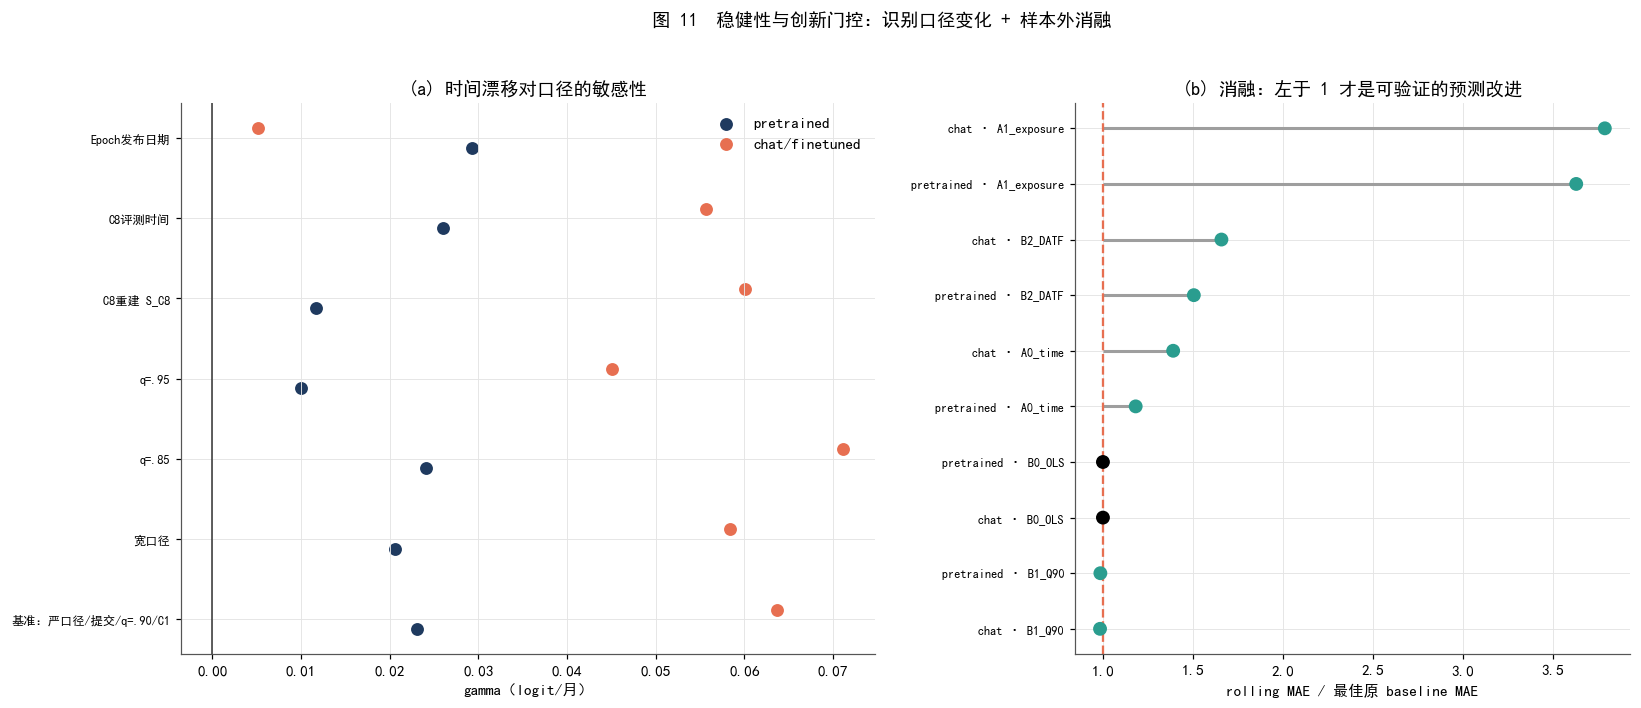

已保存 output_q4_innov/tables/q4_summary_innov.json


In [41]:
# ============ 7. 稳健性 + 消融 ============
def fit_gamma(df,q=.9,ycol='y',tcol='tau'):
    X=design(df['lnN'].values,df[tcol].values); b=quantreg(X,df[ycol].values,q); Nref=float(np.exp(np.median(df['lnN']))); bN=b[1]+2*b[2]*np.log(Nref); return b[3],float(np.exp(12*b[3]/bN)) if bN>0 else np.nan
LB['tau_pub']=(LB['date_pub']-T0).dt.days/30.4375; LB['tau_eval']=(LB['date_eval']-T0).dt.days/30.4375; LB['y_c8']=logit(np.clip(LB['S_C8']/100,1e-3,1-1e-3))
rows=[]
for g in ('pretrained','chat/finetuned'):
    base=LB[LB.type==g]
    variants=[('基准：严口径/提交/q=.90/C1',base[base.open_strict],.9,'y','tau'),('宽口径',base,.9,'y','tau'),('q=.85',base[base.open_strict],.85,'y','tau'),('q=.95',base[base.open_strict],.95,'y','tau'),('C8重建 S_C8',base[base.open_strict & base.S_C8.notna()],.9,'y_c8','tau'),('C8评测时间',base[base.open_strict & base.tau_eval.notna()],.9,'y','tau_eval'),('Epoch发布日期',base[base.open_strict & base.tau_pub.notna()],.9,'y','tau_pub')]
    for name,d,q,yc,tc in variants:
        if len(d)<40: rows.append({'类型':g,'口径':name,'n':len(d),'gamma/月':np.nan,'年参数倍数':np.nan}); continue
        gm,mult=fit_gamma(d,q,yc,tc); rows.append({'类型':g,'口径':name,'n':len(d),'gamma/月':gm,'年参数倍数':mult})
ROB=pd.DataFrame(rows); ROB.to_csv(TAB/'robustness.csv',index=False,encoding='utf-8-sig'); print('口径稳健性:'); display(ROB)

# 消融总表：以 rolling-origin MAE 为主，不拿训练内拟合优度替代预测证据
ABL=CV.copy(); ABL['相对最佳baseline_MAE']=np.nan
for g in ABL.类型.unique():
    base=ABL[(ABL.类型==g)&ABL.模型.isin(['A0_time','B0_OLS'])]['MAE'].min(); ABL.loc[ABL.类型==g,'相对最佳baseline_MAE']=ABL.loc[ABL.类型==g,'MAE']/base
ABL['是否进入最终融合']=ABL.apply(lambda r:WEIGHTS.get(r['类型'],{}).get(r['模型'],0)>0,axis=1)
ABL.to_csv(TAB/'ablation_backtest.csv',index=False,encoding='utf-8-sig'); print('\n核心消融（<1 表示比最佳原 baseline 更低 MAE）:'); display(ABL.sort_values(['类型','MAE']))

# 其他创新模块的“保留/回退”状态
STATUS=pd.DataFrame([
    {'模块':'Loss-Benchmark 权重','baseline':'High=1, Medium=.5','innovation':'tier variance IRLS','判据':'5-fold RMSE','最终':('adaptive' if USE_ADAPT else 'baseline')},
    {'模块':'算力变化点','baseline':'2023.5 固定','innovation':'q90 pinball 变化点 %.2f'%CP_YEAR,'判据':'两段 pinball loss + 稳健性','最终':'innovation + baseline sensitivity'},
    {'模块':'预测器 pretrained','baseline':'A0/B0','innovation':'EARF/Q90/DATF+ROAE','判据':'rolling-origin MAE','最终':SAFE['pretrained']},
    {'模块':'预测器 chat','baseline':'A0/B0','innovation':'EARF/Q90/DATF+ROAE','判据':'rolling-origin MAE','最终':SAFE['chat/finetuned']}
]); STATUS.to_csv(TAB/'innovation_gate_status.csv',index=False,encoding='utf-8-sig'); print('\n创新模块门控状态:'); display(STATUS)

# 图 11：口径 gamma + 回测消融 forest-like plot
fig=plt.figure(figsize=(17,6.5)); gs=gridspec.GridSpec(1,2,width_ratios=[1.25,1],wspace=.32)
ax=fig.add_subplot(gs[0]);
for g,off,c in [('pretrained',-.12,C_NAVY),('chat/finetuned',.12,C_CORAL)]:
    d=ROB[ROB.类型==g].reset_index(drop=True); yy=np.arange(len(d))+off; ax.scatter(d['gamma/月'],yy,s=55,color=c,label=g); 
ax.axvline(0,color='#333',lw=1); ax.set_yticks(np.arange(len(ROB[ROB.类型=='pretrained']))); ax.set_yticklabels(ROB[ROB.类型=='pretrained']['口径'],fontsize=8); ax.set_xlabel('gamma（logit/月）'); ax.set_title('(a) 时间漂移对口径的敏感性'); ax.legend(frameon=False)
ax=fig.add_subplot(gs[1]); dd=ABL.copy(); dd['lab']=dd['类型'].str.replace('chat/finetuned','chat')+' · '+dd['模型']; dd=dd.sort_values('相对最佳baseline_MAE'); y=np.arange(len(dd)); ax.hlines(y,1,dd['相对最佳baseline_MAE'],color=C_GREY,lw=2); ax.scatter(dd['相对最佳baseline_MAE'],y,s=65,c=['black' if x else C_TEAL for x in dd['是否进入最终融合']],zorder=3); ax.axvline(1,color=C_CORAL,lw=1.5,ls='--'); ax.set_yticks(y); ax.set_yticklabels(dd['lab'],fontsize=8); ax.set_xlabel('rolling MAE / 最佳原 baseline MAE'); ax.set_title('(b) 消融：左于 1 才是可验证的预测改进')
fig.suptitle('图 11  稳健性与创新门控：识别口径变化 + 样本外消融',fontsize=12,y=1.01); savefig('fig11_robustness_ablation.png'); plt.show()

# 最终 JSON 汇总
summary={'criteria':{'composite':'C1 Average; C8 S_C8 validation','time_axis':'submission for observed record; publication for technology clock; lag explicit in DATF'},'production':{'N_quantile':{g:{k:v for k,v in FIT[g].items() if k not in ('b','ols')} for g in FIT},'compute_candidates':MODEL_C.to_dict(orient='records')},'changepoint':{'year':CP_YEAR,'G_recent':G_RECENT,'G_fixed_2023_5':G_FIX},'bridge':{'theta':TH_B.tolist(),'use_adapt':bool(USE_ADAPT),'cv_fixed':rm_fixed,'cv_adapt':rm_adapt},'forecast_weights':WEIGHTS,'safeguard':SAFE,'calibration':CAL,'forecast':FCDF.to_dict(orient='records'),'loss_crosscheck':LOSSCH.to_dict(orient='records')}
json.dump(summary,open(TAB/'q4_summary_innov.json','w',encoding='utf-8'),ensure_ascii=False,indent=1,default=str); print('已保存 output_q4_innov/tables/q4_summary_innov.json')


## 8. 问题四结论模板（运行后按实际表格数值填入）

### 8.1 完成度

本创新版完整覆盖问题四要求：

- 综合能力：C1 六维等权 $S$，C8 39 个叶子任务独立重建 $S^{C8}$；
- 开源口径：严/宽两套，许可证与 Epoch AI 权重字段交叉核对；
- 模型类型：pretrained 与 chat/finetuned 分开；
- 时间轴：提交日期用于“被观察到的前沿”，发布日期用于“技术年代”，两者差值进入 DATF；
- 规模与非规模贡献：参数 q90 + C4 训练算力 OLS/q90/DATF + Shapley/同规模反事实；
- C8：逐任务增益、规模弹性、时间漂移，并加入 bootstrap stability；
- C6：Loss–Benchmark logistic 桥接，固定权重与异方差自适应权重经 CV 竞争；
- 未来 12/24 月：延续/放缓/停滞三种算力情景，EARF + compute-frontier 多模型滚动回测融合；
- 不确定性：模型级 Bootstrap + rolling residual calibration；
- 前三问接口：继续使用问题三 $L^\star(C)$，但把差值表述为“**桥接未解释增益**”，不无证据地命名为某一类技术的因果贡献。

### 8.2 三个可写进论文的主创新

**创新 1：Delay-Aware Dual-Time Frontier。** 将发布日期与提交日期分离，显式建模发布—提交延迟，降低把社区扩散、评测时滞误判为算法进步的风险；并把 OLS、q90、DATF 放入统一样本外竞争框架。

**创新 2：Exposure-Aware Record Frontier。** 把纪录刷新中的“累计候选模型暴露量”与“纯时间漂移”分离，比只用 $\ln(1+t)$ 更符合极值来自样本数量的机制解释。

**创新 3：Rolling-Origin Adaptive Ensemble with Safeguard。** 多历史截断点评估五个候选，基于样本外 MAE 自适应融合；如果创新融合不优于原 baseline，自动回退。该机制使“至少不因创新而破坏基线”成为可复现的模型选择规则，而不是口头承诺。

### 8.3 论文中必须避免的过度表述

1. `gamma` 是控制观测规模后的时间漂移，不等价于“纯算法因果效应”；DATF 只是进一步减少一种可观测混杂。
2. $\Delta S_{ROAE}-\Delta S_{Loss}$ 统一称为 **Loss 桥接未解释增益**，其中可能包含后训练、数据工程、架构变化、benchmark-specific improvement 和桥接误差。
3. conformal-inspired 校准基于滚动残差；由于存在时间漂移，不宣称经典 exchangeability 条件下的严格有限样本覆盖保证。

## 9. 方法参考文献

[1] Ho, A., Besiroglu, T., Erdil, E., et al. **Algorithmic Progress in Language Models**. arXiv:2403.05812, 2024.  
https://arxiv.org/abs/2403.05812  
**本文借鉴**：augmented scaling law、算法进步的等效算力解释、规模与时间因素分解。

[2] Koenker, R., & Bassett, G. **Regression Quantiles**. *Econometrica*, 46(1):33–50, 1978. DOI: 10.2307/1913643.  
**本文借鉴**：q=0.9 条件前沿建模，而非均值回归。

[3] Hoffmann, J., Borgeaud, S., Mensch, A., et al. **Training Compute-Optimal Large Language Models**. NeurIPS 2022.  
https://arxiv.org/abs/2203.15556  
**本文借鉴**：不能仅把参数量视为规模；训练 compute 与数据/参数联合决定能力前沿。

[4] Romano, Y., Patterson, E., & Candès, E. **Conformalized Quantile Regression**. NeurIPS 2019.  
https://proceedings.neurips.cc/paper/2019/hash/5103c3584b063c431bd1268e9b5e76fb-Abstract.html  
**本文借鉴**：利用样本外残差对预测区间进行覆盖校准的思想。

[5] Gibbs, I., & Candès, E. **Adaptive Conformal Inference Under Distribution Shift**. NeurIPS 2021.  
https://proceedings.neurips.cc/paper/2021/hash/0d441de75945e5acbc865406fc9a2559-Abstract.html  
**本文借鉴**：时间分布漂移下，静态区间校准可能失效，应使用随时间更新的误差信息。本 notebook 采用简化的 rolling-residual calibration，并明确不声称完整 ACI 理论保证。

[6] Hyndman, R. J., & Athanasopoulos, G. **Forecasting: Principles and Practice**, 3rd ed., Section 5.10 Time series cross-validation.  
https://otexts.robjhyndman.com/fpp3/tscv.html  
**本文借鉴**：rolling forecasting origin，确保每个回测 fold 只使用预测时点之前的信息。

---

### 输出目录
运行后结果全部写入 `output_q4_innov/`：核心表包括 `rolling_origin_backtest.csv`、`ablation_backtest.csv`、`compute_tech_model_candidates.csv`、`compute_changepoint_search.csv`、`frontier_forecast.csv`、`innovation_gate_status.csv`、`q4_summary_innov.json`；图包括原版保留图以及新增 `fig06b_dual_time_diagnostic.png`、`fig08_compute_changepoint_scenarios.png`、`fig10_roae_forecast.png`、`fig11_robustness_ablation.png`。
